# learning curve

## smoothed option added

Processing block transitions (Applying 1-Trial Smoothing)...
Reaction-time plots exclude 97 trials with at least one negative lick time in the full lick array.
Drawing smoothed subplots (this may take a moment to calculate rolling CIs)...
Done! Figure saved to block_transition_dynamics_smoothed.png


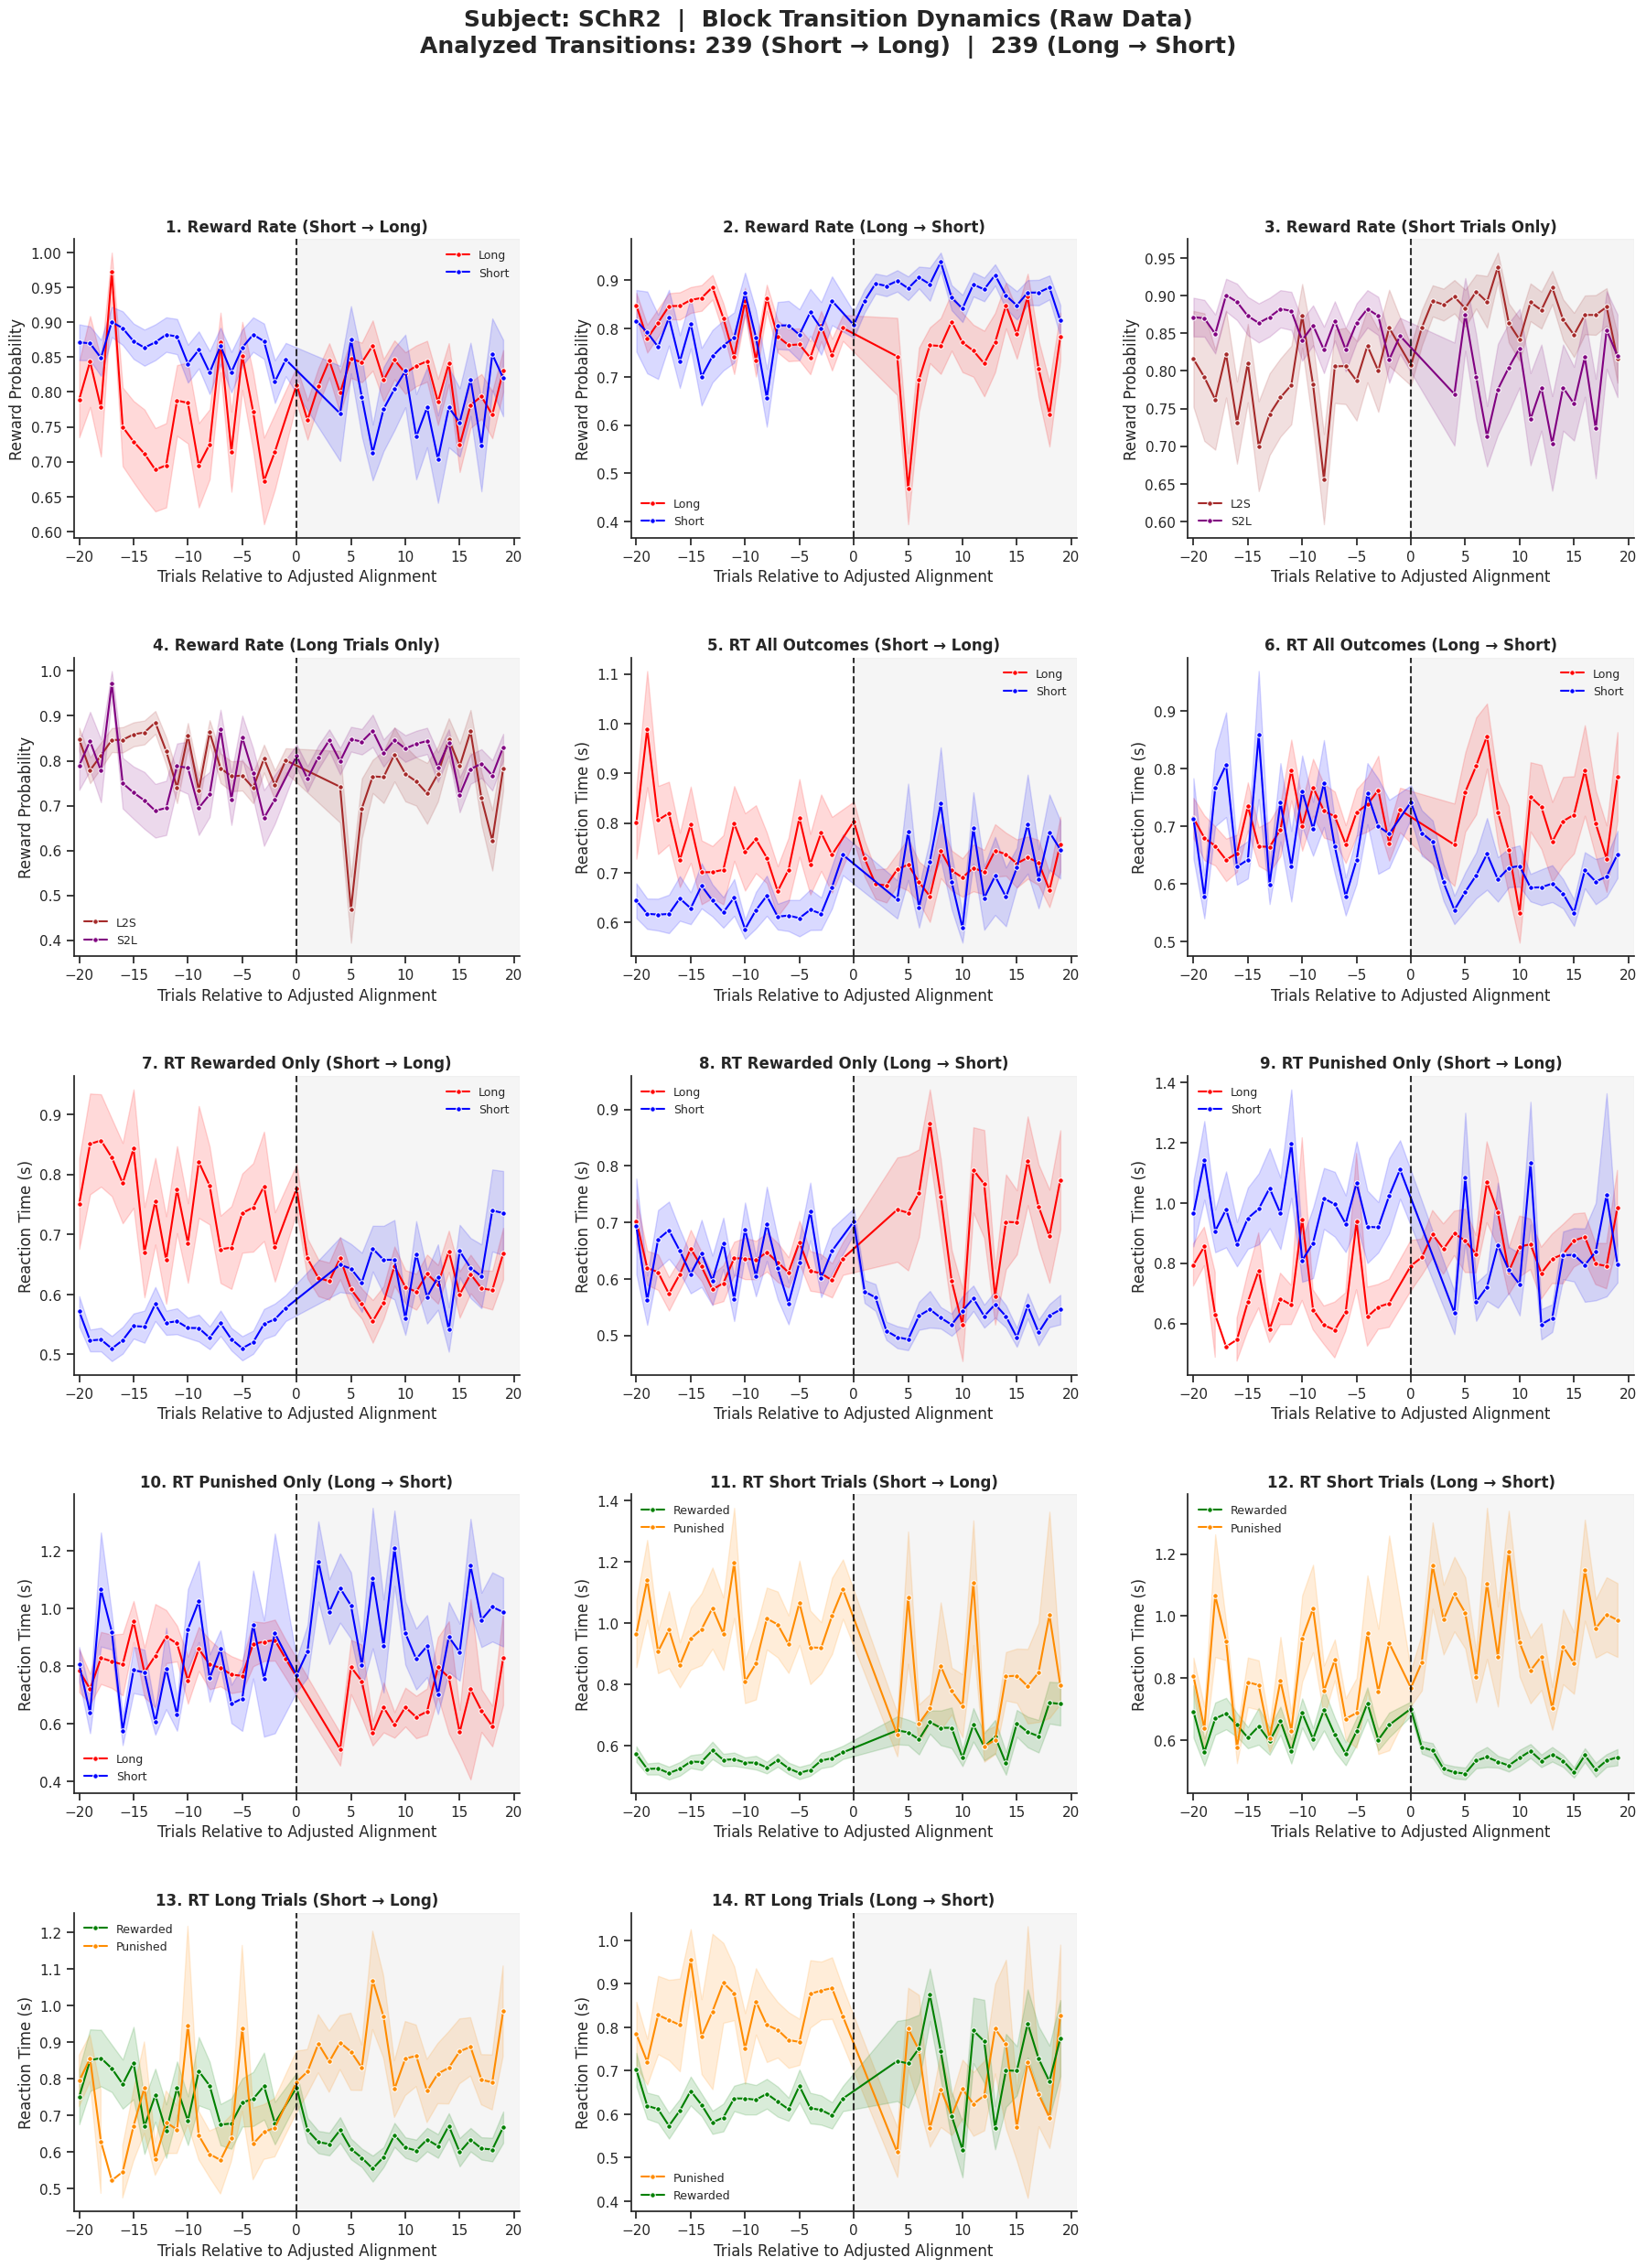

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
import os
import ast
import json

warnings.filterwarnings('ignore')
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["text.usetex"] = False
plt.rcParams["savefig.dpi"] = 600

# ==========================================
# SETTING: Adjust the smoothing strength here
# Standard values are 3, 5, or 7 trials. 
# Set to 1 to turn smoothing off completely.
# ==========================================
SMOOTHING_WINDOW = 1
FIRST_BLOCK_TRIALS_FORCED_COMMON = 4
# ==========================================

NEGATIVE_LICK_ARRAY_COLUMNS = ['all_lick_reaction_times', 'all_lick_start_times_from_choice']
NEGATIVE_LICK_DETAIL_KEYS = ['reaction_time', 'start_time_from_choice']
RT_NEGATIVE_LICK_FLAG = 'rt_excluded_negative_lick_array'


def _load_lick_array_value(value):
    if value is None:
        return []
    if isinstance(value, float) and np.isnan(value):
        return []
    if isinstance(value, str):
        text = value.strip()
        if not text or text.lower() in {'nan', 'none', 'null'}:
            return []
        try:
            return json.loads(text)
        except (json.JSONDecodeError, TypeError):
            try:
                return ast.literal_eval(text)
            except (ValueError, SyntaxError):
                return []
    return value


def _iter_relative_lick_times(value):
    value = _load_lick_array_value(value)
    if isinstance(value, dict):
        for key in NEGATIVE_LICK_DETAIL_KEYS:
            if key in value:
                yield value[key]
        return
    if isinstance(value, (list, tuple, np.ndarray)):
        for item in value:
            yield from _iter_relative_lick_times(item)
        return
    yield value


def has_negative_lick_time(value):
    for item in _iter_relative_lick_times(value):
        if item is None:
            continue
        try:
            if pd.notna(item) and float(item) < 0:
                return True
        except (TypeError, ValueError):
            continue
    return False


def get_negative_lick_array_mask(df):
    mask = pd.Series(False, index=df.index)
    columns = [column for column in NEGATIVE_LICK_ARRAY_COLUMNS if column in df.columns]

    for column in columns:
        mask = mask | df[column].apply(has_negative_lick_time)

    if not columns and 'all_lick_details' in df.columns:
        mask = mask | df['all_lick_details'].apply(has_negative_lick_time)

    return mask


def add_rt_exclusion_flag(df):
    df = df.copy()
    df[RT_NEGATIVE_LICK_FLAG] = get_negative_lick_array_mask(df)
    return df


def get_valid_reaction_time(row):
    excluded = row.get(RT_NEGATIVE_LICK_FLAG, False)
    if pd.notna(excluded) and bool(excluded):
        return np.nan
    reaction_time = pd.to_numeric(row.get('lick_reaction_time', np.nan), errors='coerce')
    if not np.isfinite(reaction_time) or reaction_time < 0:
        return np.nan
    return float(reaction_time)


def mask_early_block_rare_trials(sdf, n_first=FIRST_BLOCK_TRIALS_FORCED_COMMON):
    """Set rare labels in the first n trials of each block to NaN for analysis."""
    sdf = sdf.copy()
    block_run = sdf['block_type'].ne(sdf['block_type'].shift()).cumsum()
    sdf['trial_in_block'] = sdf.groupby(block_run, sort=False).cumcount() + 1
    raw_rare = (
        (sdf['block_type'].eq(1) & sdf['trial_type'].eq(2)) |
        (sdf['block_type'].eq(2) & sdf['trial_type'].eq(1))
    )
    early_rare = raw_rare & sdf['trial_in_block'].le(n_first)
    sdf['analysis_trial_type'] = sdf['trial_type'].mask(early_rare)
    sdf['analysis_is_rare'] = raw_rare.astype(float).mask(early_rare)
    sdf['early_block_rare_masked'] = early_rare
    return sdf


def is_rare_trial(row):
    if 'analysis_is_rare' in row.index:
        return row.get('analysis_is_rare') == 1
    return ((row.get('block_type') == 1 and row.get('trial_type') == 2) or
            (row.get('block_type') == 2 and row.get('trial_type') == 1))


def get_adjusted_alignment_index(sdf, formal_switch_idx, prev_block):
    """
    If the previous block ends with one or more rare trials, align to the
    first trial in that terminal rare run. Otherwise align to the formal switch.
    """
    last_prev_idx = formal_switch_idx - 1
    if last_prev_idx < 0 or not is_rare_trial(sdf.loc[last_prev_idx]):
        return formal_switch_idx

    align_idx = last_prev_idx
    while align_idx - 1 >= 0:
        prev_row = sdf.loc[align_idx - 1]
        if prev_row.get('block_type') != prev_block or not is_rare_trial(prev_row):
            break
        align_idx -= 1

    return align_idx


def nan_mean_sem(values):
    """Return an explicitly NaN-aware mean and SEM without filling missing trials."""
    array = pd.to_numeric(pd.Series(values), errors='coerce').to_numpy(float)
    finite = array[np.isfinite(array)]
    if len(finite) == 0:
        return np.nan, np.nan
    mean = float(np.nanmean(finite))
    sem = float(np.nanstd(finite, ddof=1) / np.sqrt(len(finite))) if len(finite) > 1 else np.nan
    return mean, sem


def match_primary_y_limits(*axes):
    """Apply the union of the current primary-axis limits to every supplied axis."""
    limits = [axis.get_ylim() for axis in axes]
    lower = min(limit[0] for limit in limits)
    upper = max(limit[1] for limit in limits)
    for axis in axes:
        axis.set_ylim(lower, upper)


def plot_trace(ax, data, x, y, hue, palette, title, ylabel,
               window=SMOOTHING_WINDOW, bridge_previous_same_type=True):
    if data.empty or data[y].isna().all():
        ax.set_title(title + " (No Data)")
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        return
        
    # 1. Create a working copy and define the strict phase boundaries around alignment
    plot_df = data.copy()
    plot_df['phase'] = np.where(plot_df[x] < 0, 'Pre', 'Post')
    plot_df['rare_rate'] = pd.to_numeric(plot_df['is_rare'], errors='coerce')
    
    # 2. Sort values strictly by Transition ID and Relative Trial
    plot_df = plot_df.sort_values(['trans_id', x])
    y_was_present = plot_df[y].notna()
    rare_was_present = plot_df['rare_rate'].notna()
    
    # 3. Apply Phase-Isolated Centered Smoothing
    # By grouping by trans_id, phase, and hue, we ensure we NEVER smooth across x=0,
    # and we NEVER smooth across different trial types or different transitions.
    if window > 1:
        plot_df[y] = plot_df.groupby(['trans_id', 'phase', hue])[y].transform(
            lambda val: val.rolling(window=window, min_periods=1, center=True).mean()
        ).where(y_was_present)
        plot_df['rare_rate'] = plot_df.groupby(['trans_id', 'phase'])['rare_rate'].transform(
            lambda val: val.rolling(window=window, min_periods=1, center=True).mean()
        ).where(rare_was_present)

    # A condition can have no physical observation at -1 by construction. For
    # every missing transition x condition combination, duplicate its last valid
    # matching pre-alignment observation at x=-1 as an explicitly marked bridge.
    # Real x=-1 observations remain untouched and filled.
    rare_source_df = plot_df.copy()
    plot_df['bridge_proxy'] = False
    if bridge_previous_same_type:
        bridge_rows = []
        for hue_value, hue_data in plot_df.groupby(hue, sort=False, dropna=True):
            has_visible_minus_one = hue_data[x].eq(-1) & hue_data[y].notna()
            if has_visible_minus_one.any():
                continue
            for _, transition_data in hue_data.groupby('trans_id', sort=False):
                candidates = transition_data[
                    transition_data[x].lt(0) & transition_data[y].notna()
                ].sort_values(x)
                if candidates.empty:
                    continue
                proxy = candidates.iloc[-1].copy()
                proxy[x] = -1
                proxy['bridge_proxy'] = True
                bridge_rows.append(proxy)
        if bridge_rows:
            plot_df = pd.concat([plot_df, pd.DataFrame(bridge_rows)], ignore_index=True)
        
    # Plot explicit NaN-aware means and SEMs. Missing trial-type positions have
    # no marker; plotting only finite points connects the surrounding line.
    full_x = np.arange(-20, 20)
    bridge_label_added = False
    for hue_value in pd.unique(plot_df[hue].dropna()):
        hue_data = plot_df[plot_df[hue].eq(hue_value)]
        if hue_data[y].notna().sum() == 0:
            continue
        rows = []
        for x_value, group in hue_data.groupby(x):
            mean, sem = nan_mean_sem(group[y])
            rows.append({x: x_value, 'mean': mean, 'sem': sem})
        summary = pd.DataFrame(rows).set_index(x).reindex(full_x)
        color = palette.get(hue_value, 'black')
        visible = summary['mean'].notna()
        ax.plot(summary.index[visible], summary.loc[visible, 'mean'], color=color, marker='o', markersize=4,
                linewidth=1.8, label=str(hue_value))
        # Bridge bounded missing trial-type sequences in the SEM envelope by
        # linearly connecting the last available band before the gap to the
        # first available band after it. Edge gaps remain unfilled.
        band_mean = summary['mean'].interpolate(method='linear', limit_area='inside')
        band_sem = summary['sem'].interpolate(method='linear', limit_area='inside')
        band = band_mean.notna() & band_sem.notna()
        ax.fill_between(full_x, band_mean - band_sem,
                        band_mean + band_sem, where=band,
                        color=color, alpha=0.15)
        hue_has_bridge = plot_df.loc[plot_df[hue].eq(hue_value), 'bridge_proxy'].any()
        if hue_has_bridge and np.isfinite(summary.loc[-1, 'mean']):
            bridge_label = 'Previous matching trial' if not bridge_label_added else None
            ax.scatter(-1, summary.loc[-1, 'mean'], s=38, facecolors='white',
                       edgecolors=color, linewidths=1.5, zorder=5, label=bridge_label)
            bridge_label_added = True

    # Rare-trial rate is the mean of the binary rare indicator at each aligned trial.
    # Draw it on a secondary 0-1 axis so the same gray trace is interpretable on
    # both reward-probability and reaction-time panels.
    rare_rows = []
    for x_value, group in rare_source_df.groupby(x):
        mean, sem = nan_mean_sem(group['rare_rate'])
        rare_rows.append({x: x_value, 'mean': mean, 'sem': sem})
    rare_trace = pd.DataFrame(rare_rows).set_index(x).reindex(full_x)
    rare_ax = ax.twinx()
    rare_ax.plot(
        full_x, rare_trace['mean'], color='gray', linewidth=1.8,
        alpha=0.85, label='Rare-trial rate', zorder=1,
    )
    rare_band = rare_trace['mean'].notna() & rare_trace['sem'].notna()
    rare_ax.fill_between(full_x, rare_trace['mean'] - rare_trace['sem'],
                         rare_trace['mean'] + rare_trace['sem'], where=rare_band,
                         color='gray', alpha=0.12, zorder=0)
    rare_ax.set_ylim(-0.05, 1.05)
    rare_ax.set_ylabel('Rare-trial rate', color='gray', fontsize=8)
    rare_ax.set_yticks([0, 0.5, 1.0], ['0%', '50%', '100%'])
    rare_ax.tick_params(axis='y', colors='gray', labelsize=7)
    rare_ax.spines['top'].set_visible(False)
    rare_ax.spines['right'].set_color('gray')
    
    # Visual aides for the adjusted alignment event
    ax.axvline(0, color='black', linestyle='--', alpha=0.8, linewidth=1.5)
    ax.axvspan(0, 20.5, color='gray', alpha=0.08) # Shade the new block
    
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Trials Relative to Adjusted Alignment')
    ax.set_xlim(-20.5, 20.5)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    primary_handles, primary_labels = ax.get_legend_handles_labels()
    rare_handles, rare_labels = rare_ax.get_legend_handles_labels()
    if primary_handles or rare_handles:
        ax.legend(primary_handles + rare_handles, primary_labels + rare_labels,
                  title='', frameon=False, loc='best', fontsize=8)

def main():
    csv_path = input("Enter the path to your CSV file (e.g., sample_data.csv): ").strip()
    if not os.path.exists(csv_path):
        print(f"File not found: {csv_path}. Please check the path and try again.")
        return

    save_dir = input("Enter the directory to save the figure (e.g., ./plots/): ").strip()
    if save_dir and not os.path.exists(save_dir):
        os.makedirs(save_dir)
        print(f"Created directory: {save_dir}")
    if save_dir and not save_dir.endswith(os.sep):
        save_dir += os.sep
        
    print(f"Processing block transitions (Applying {SMOOTHING_WINDOW}-Trial Smoothing)...")

    df = pd.read_csv(csv_path)
    df = add_rt_exclusion_flag(df)
    n_rt_excluded = int(df[RT_NEGATIVE_LICK_FLAG].sum())
    print(f"Reaction-time plots exclude {n_rt_excluded} trials with at least one negative lick time in the full lick array.")
    
    # --------------------------------------------------------
    # 1. EXTRACT TRANSITION DATA
    # --------------------------------------------------------
    trans_data = []
    trans_id = 0
    n_s2l = 0
    n_l2s = 0
    
    for sess, sdf in df.groupby('session_idx'):
        if 'trial_num' in sdf.columns:
            sdf = sdf.sort_values('trial_num').reset_index(drop=True)
        else:
            sdf = sdf.reset_index(drop=True)
        sdf = mask_early_block_rare_trials(sdf)
            
        sdf['block_change'] = sdf['block_type'] != sdf['block_type'].shift(1)
        transitions = sdf.index[sdf['block_change'] & sdf['block_type'].shift(1).notna()].tolist()
        
        for t_idx in transitions:
            prev_block = sdf.loc[t_idx - 1, 'block_type']
            curr_block = sdf.loc[t_idx, 'block_type']
            
            if prev_block == 1 and curr_block == 2:
                t_type = 'S2L'
                n_s2l += 1
            elif prev_block == 2 and curr_block == 1:
                t_type = 'L2S'
                n_l2s += 1
            else:
                continue 
                
            trans_id += 1
            
            align_idx = get_adjusted_alignment_index(sdf, t_idx, prev_block)
            alignment_shift = t_idx - align_idx
            
            # Restrict the aligned window to the immediately adjacent previous
            # and current blocks. Positions outside those two blocks are padded
            # with NaN instead of borrowing trials from neighboring blocks.
            previous_block_start = t_idx - 1
            while (previous_block_start - 1 >= 0 and
                   sdf.loc[previous_block_start - 1, 'block_type'] == prev_block):
                previous_block_start -= 1
            current_block_end = t_idx
            while (current_block_end + 1 < len(sdf) and
                   sdf.loc[current_block_end + 1, 'block_type'] == curr_block):
                current_block_end += 1
            
            for rel_t in range(-20, 20):
                i = align_idx + rel_t
                if i < previous_block_start or i > current_block_end:
                    trans_data.append({
                        'trans_id': trans_id,
                        'trans_type': t_type,
                        'formal_switch_rel_trial': alignment_shift,
                        'alignment_shift': alignment_shift,
                        'aligned_on_terminal_rare': alignment_shift > 0,
                        'rel_trial': rel_t,
                        'block_type': np.nan,
                        'trial_type': np.nan,
                        'trial_type_name': np.nan,
                        'is_rare': np.nan,
                        'outcome_type': np.nan,
                        'rewarded': np.nan,
                        'rt': np.nan,
                    })
                    continue
                
                row = sdf.loc[i]
                
                out_str = str(row.get('outcome', '')).lower()
                if 'reward' in out_str:
                    outcome_type = 'Rewarded'
                    rew_val = 1.0
                elif 'punish' in out_str:
                    outcome_type = 'Punished'
                    rew_val = 0.0
                else:
                    outcome_type = 'Other'
                    rew_val = np.nan 
                    
                tt = row.get('analysis_trial_type', np.nan)
                if pd.isna(tt):
                    tt_name = np.nan
                elif tt == 1:
                    tt_name = 'Short'
                elif tt == 2:
                    tt_name = 'Long'
                else:
                    tt_name = 'Other'
                    
                rt = get_valid_reaction_time(row)
                
                trans_data.append({
                    'trans_id': trans_id,
                    'trans_type': t_type,
                    'formal_switch_rel_trial': alignment_shift,
                    'alignment_shift': alignment_shift,
                    'aligned_on_terminal_rare': alignment_shift > 0,
                    'rel_trial': rel_t,
                    'block_type': row.get('block_type', np.nan),
                    'trial_type': tt,
                    'trial_type_name': tt_name,
                    'is_rare': row.get('analysis_is_rare', np.nan),
                    'outcome_type': outcome_type,
                    'rewarded': rew_val,
                    'rt': rt
                })
                
    df_t = pd.DataFrame(trans_data)
    
    if df_t.empty:
        print("No valid Short<->Long transitions found in this dataset.")
        return

    # --------------------------------------------------------
    # 2. PLOTTING SETUP
    # --------------------------------------------------------
    fig = plt.figure(figsize=(22, 34))
    if 'subject' in df.columns:
        subjects = sorted(df['subject'].dropna().astype(str).unique())
        subject = ', '.join(subjects) if len(subjects) <= 4 else f'{len(subjects)} subjects'
    else:
        subject = "Unknown"
    smooth_txt = f"({SMOOTHING_WINDOW}-Trial Centered Smoothing)" if SMOOTHING_WINDOW > 1 else "(Raw Data)"
    
    fig.suptitle(f"Subject: {subject}  |  Block Transition Dynamics {smooth_txt}\n"
                 f"Analyzed Transitions: {n_s2l} (Short \u2192 Long)  |  {n_l2s} (Long \u2192 Short)", 
                 fontsize=18, fontweight='bold', y=0.985)

    gs = gridspec.GridSpec(6, 3, figure=fig, hspace=0.4, wspace=0.25)
    
    pal_tt = {'Short': 'blue', 'Long': 'red'}
    pal_trans = {'S2L': 'purple', 'L2S': 'brown'}
    pal_out = {'Rewarded': 'green', 'Punished': 'darkorange'}
    pal_fraction = {'Short \u2192 Long': '#2ca02c', 'Long \u2192 Short': '#008080'}

    df_s2l = df_t[df_t['trans_type'] == 'S2L'].copy()
    df_l2s = df_t[df_t['trans_type'] == 'L2S'].copy()
    df_s2l['fraction_group'] = 'Short \u2192 Long'
    df_l2s['fraction_group'] = 'Long \u2192 Short'
    df_short = df_t[df_t['trial_type_name'] == 'Short']
    df_long = df_t[df_t['trial_type_name'] == 'Long']

    print("Drawing smoothed subplots (this may take a moment to calculate rolling CIs)...")

    # --- ROW 1: Reward Rates ---
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    plot_trace(ax1, df_s2l, 'rel_trial', 'rewarded', 'trial_type_name', pal_tt, 
               '1. Reward Rate (Short \u2192 Long)', 'Reward Probability')
    plot_trace(ax2, df_l2s, 'rel_trial', 'rewarded', 'trial_type_name', pal_tt, 
               '2. Reward Rate (Long \u2192 Short)', 'Reward Probability')
    match_primary_y_limits(ax1, ax2)
    plot_trace(fig.add_subplot(gs[0, 2]), df_short, 'rel_trial', 'rewarded', 'trans_type', pal_trans, 
               '3. Reward Rate (Short Trials Only)', 'Reward Probability')

    # --- ROW 2: Reward Rates (cont) & RT All ---
    plot_trace(fig.add_subplot(gs[1, 0]), df_long, 'rel_trial', 'rewarded', 'trans_type', pal_trans, 
               '4. Reward Rate (Long Trials Only)', 'Reward Probability')
    plot_trace(fig.add_subplot(gs[1, 1]), df_s2l, 'rel_trial', 'rt', 'trial_type_name', pal_tt, 
               '5. RT All Outcomes (Short \u2192 Long)', 'Reaction Time (s)')
    plot_trace(fig.add_subplot(gs[1, 2]), df_l2s, 'rel_trial', 'rt', 'trial_type_name', pal_tt, 
               '6. RT All Outcomes (Long \u2192 Short)', 'Reaction Time (s)')

    # --- ROW 3: RT Rewarded & Punished ---
    plot_trace(fig.add_subplot(gs[2, 0]), df_s2l[df_s2l['outcome_type'] == 'Rewarded'], 'rel_trial', 'rt', 'trial_type_name', pal_tt, 
               '7. RT Rewarded Only (Short \u2192 Long)', 'Reaction Time (s)')
    plot_trace(fig.add_subplot(gs[2, 1]), df_l2s[df_l2s['outcome_type'] == 'Rewarded'], 'rel_trial', 'rt', 'trial_type_name', pal_tt, 
               '8. RT Rewarded Only (Long \u2192 Short)', 'Reaction Time (s)')
    plot_trace(fig.add_subplot(gs[2, 2]), df_s2l[df_s2l['outcome_type'] == 'Punished'], 'rel_trial', 'rt', 'trial_type_name', pal_tt, 
               '9. RT Punished Only (Short \u2192 Long)', 'Reaction Time (s)')

    # --- ROW 4: RT Punished (cont) & Outcome Overlays (Short) ---
    plot_trace(fig.add_subplot(gs[3, 0]), df_l2s[df_l2s['outcome_type'] == 'Punished'], 'rel_trial', 'rt', 'trial_type_name', pal_tt, 
               '10. RT Punished Only (Long \u2192 Short)', 'Reaction Time (s)')
    ax11 = fig.add_subplot(gs[3, 1])
    ax12 = fig.add_subplot(gs[3, 2])
    plot_trace(ax11, df_short[(df_short['trans_type'] == 'S2L') & df_short['outcome_type'].isin(['Rewarded', 'Punished'])], 
               'rel_trial', 'rt', 'outcome_type', pal_out, 
               '11. RT Short Trials (Short \u2192 Long)', 'Reaction Time (s)')
    plot_trace(ax12, df_short[(df_short['trans_type'] == 'L2S') & df_short['outcome_type'].isin(['Rewarded', 'Punished'])], 
               'rel_trial', 'rt', 'outcome_type', pal_out, 
               '12. RT Short Trials (Long \u2192 Short)', 'Reaction Time (s)',
               bridge_previous_same_type=True)

    # --- ROW 5: Outcome Overlays (Long) ---
    ax13 = fig.add_subplot(gs[4, 0])
    ax14 = fig.add_subplot(gs[4, 1])
    plot_trace(ax13, df_long[(df_long['trans_type'] == 'S2L') & df_long['outcome_type'].isin(['Rewarded', 'Punished'])], 
               'rel_trial', 'rt', 'outcome_type', pal_out, 
               '13. RT Long Trials (Short \u2192 Long)', 'Reaction Time (s)',
               bridge_previous_same_type=True)
    plot_trace(ax14, df_long[(df_long['trans_type'] == 'L2S') & df_long['outcome_type'].isin(['Rewarded', 'Punished'])], 
               'rel_trial', 'rt', 'outcome_type', pal_out, 
               '14. RT Long Trials (Long \u2192 Short)', 'Reaction Time (s)')
    match_primary_y_limits(ax11, ax12, ax13, ax14)

    # --- ROW 6: Overall Fraction Rewarded ---
    ax15 = fig.add_subplot(gs[5, 0])
    ax16 = fig.add_subplot(gs[5, 1])
    plot_trace(ax15, df_s2l, 'rel_trial', 'rewarded', 'fraction_group', pal_fraction,
               '15. Fraction Rewarded (Short \u2192 Long)', 'Fraction Rewarded')
    plot_trace(ax16, df_l2s, 'rel_trial', 'rewarded', 'fraction_group', pal_fraction,
               '16. Fraction Rewarded (Long \u2192 Short)', 'Fraction Rewarded')
    match_primary_y_limits(ax15, ax16)
    fig.add_subplot(gs[5, 2]).axis('off')

    save_path = os.path.join(save_dir, 'block_transition_dynamics_smoothed.pdf')
    plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white')
    print(f"Done! Figure saved to {save_path}")
    plt.show()

if __name__ == '__main__':
    main()

## adaptation

Reaction-time plots exclude 97 trials with at least one negative lick time in the full lick array.
Transitions found:
trans_type
L2S    239
S2L    239
Name: trans_id, dtype: int64

Terminal-rare adjusted alignments:
trans_type
S2L    73
L2S    58
Name: trans_id, dtype: int64

Alignment shift summary, trials before formal switch:
            count      mean       std  min  25%  50%  75%  max
trans_type                                                    
L2S          58.0  1.258621  0.515049  1.0  1.0  1.0  1.0  3.0
S2L          73.0  1.287671  0.564689  1.0  1.0  1.0  1.0  3.0


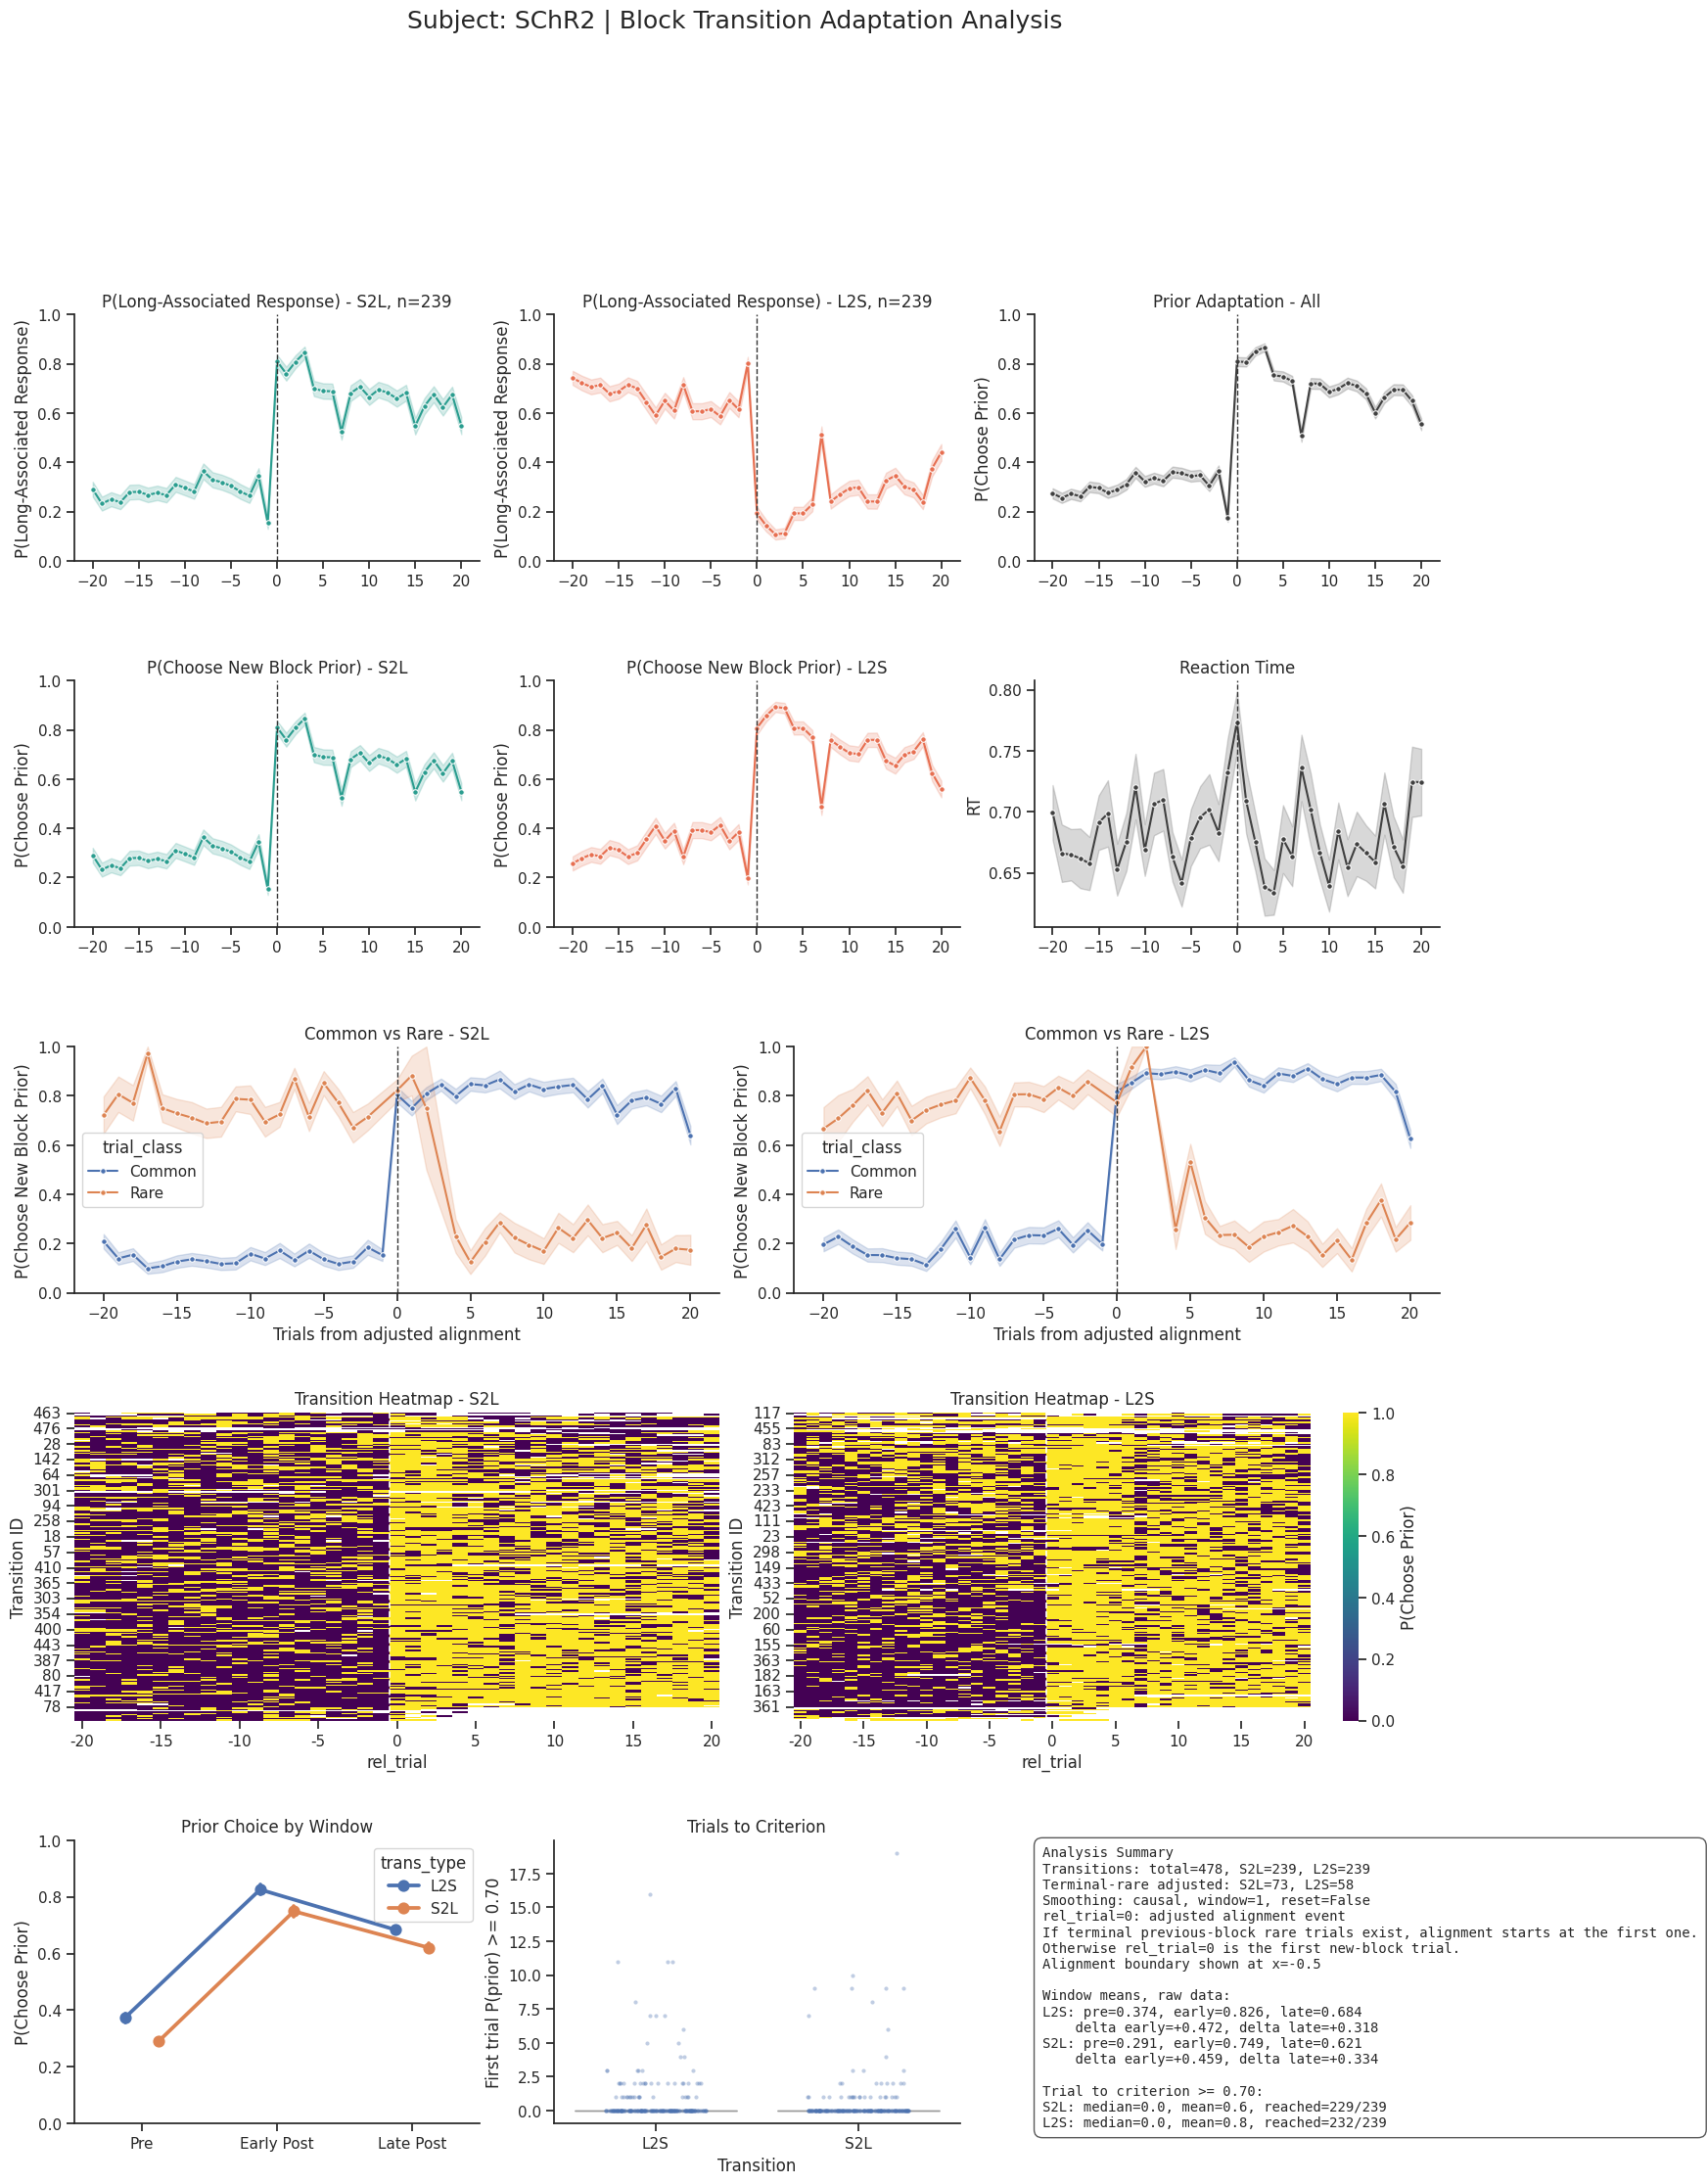

Saved figure to: transition_adaptation_summary.png


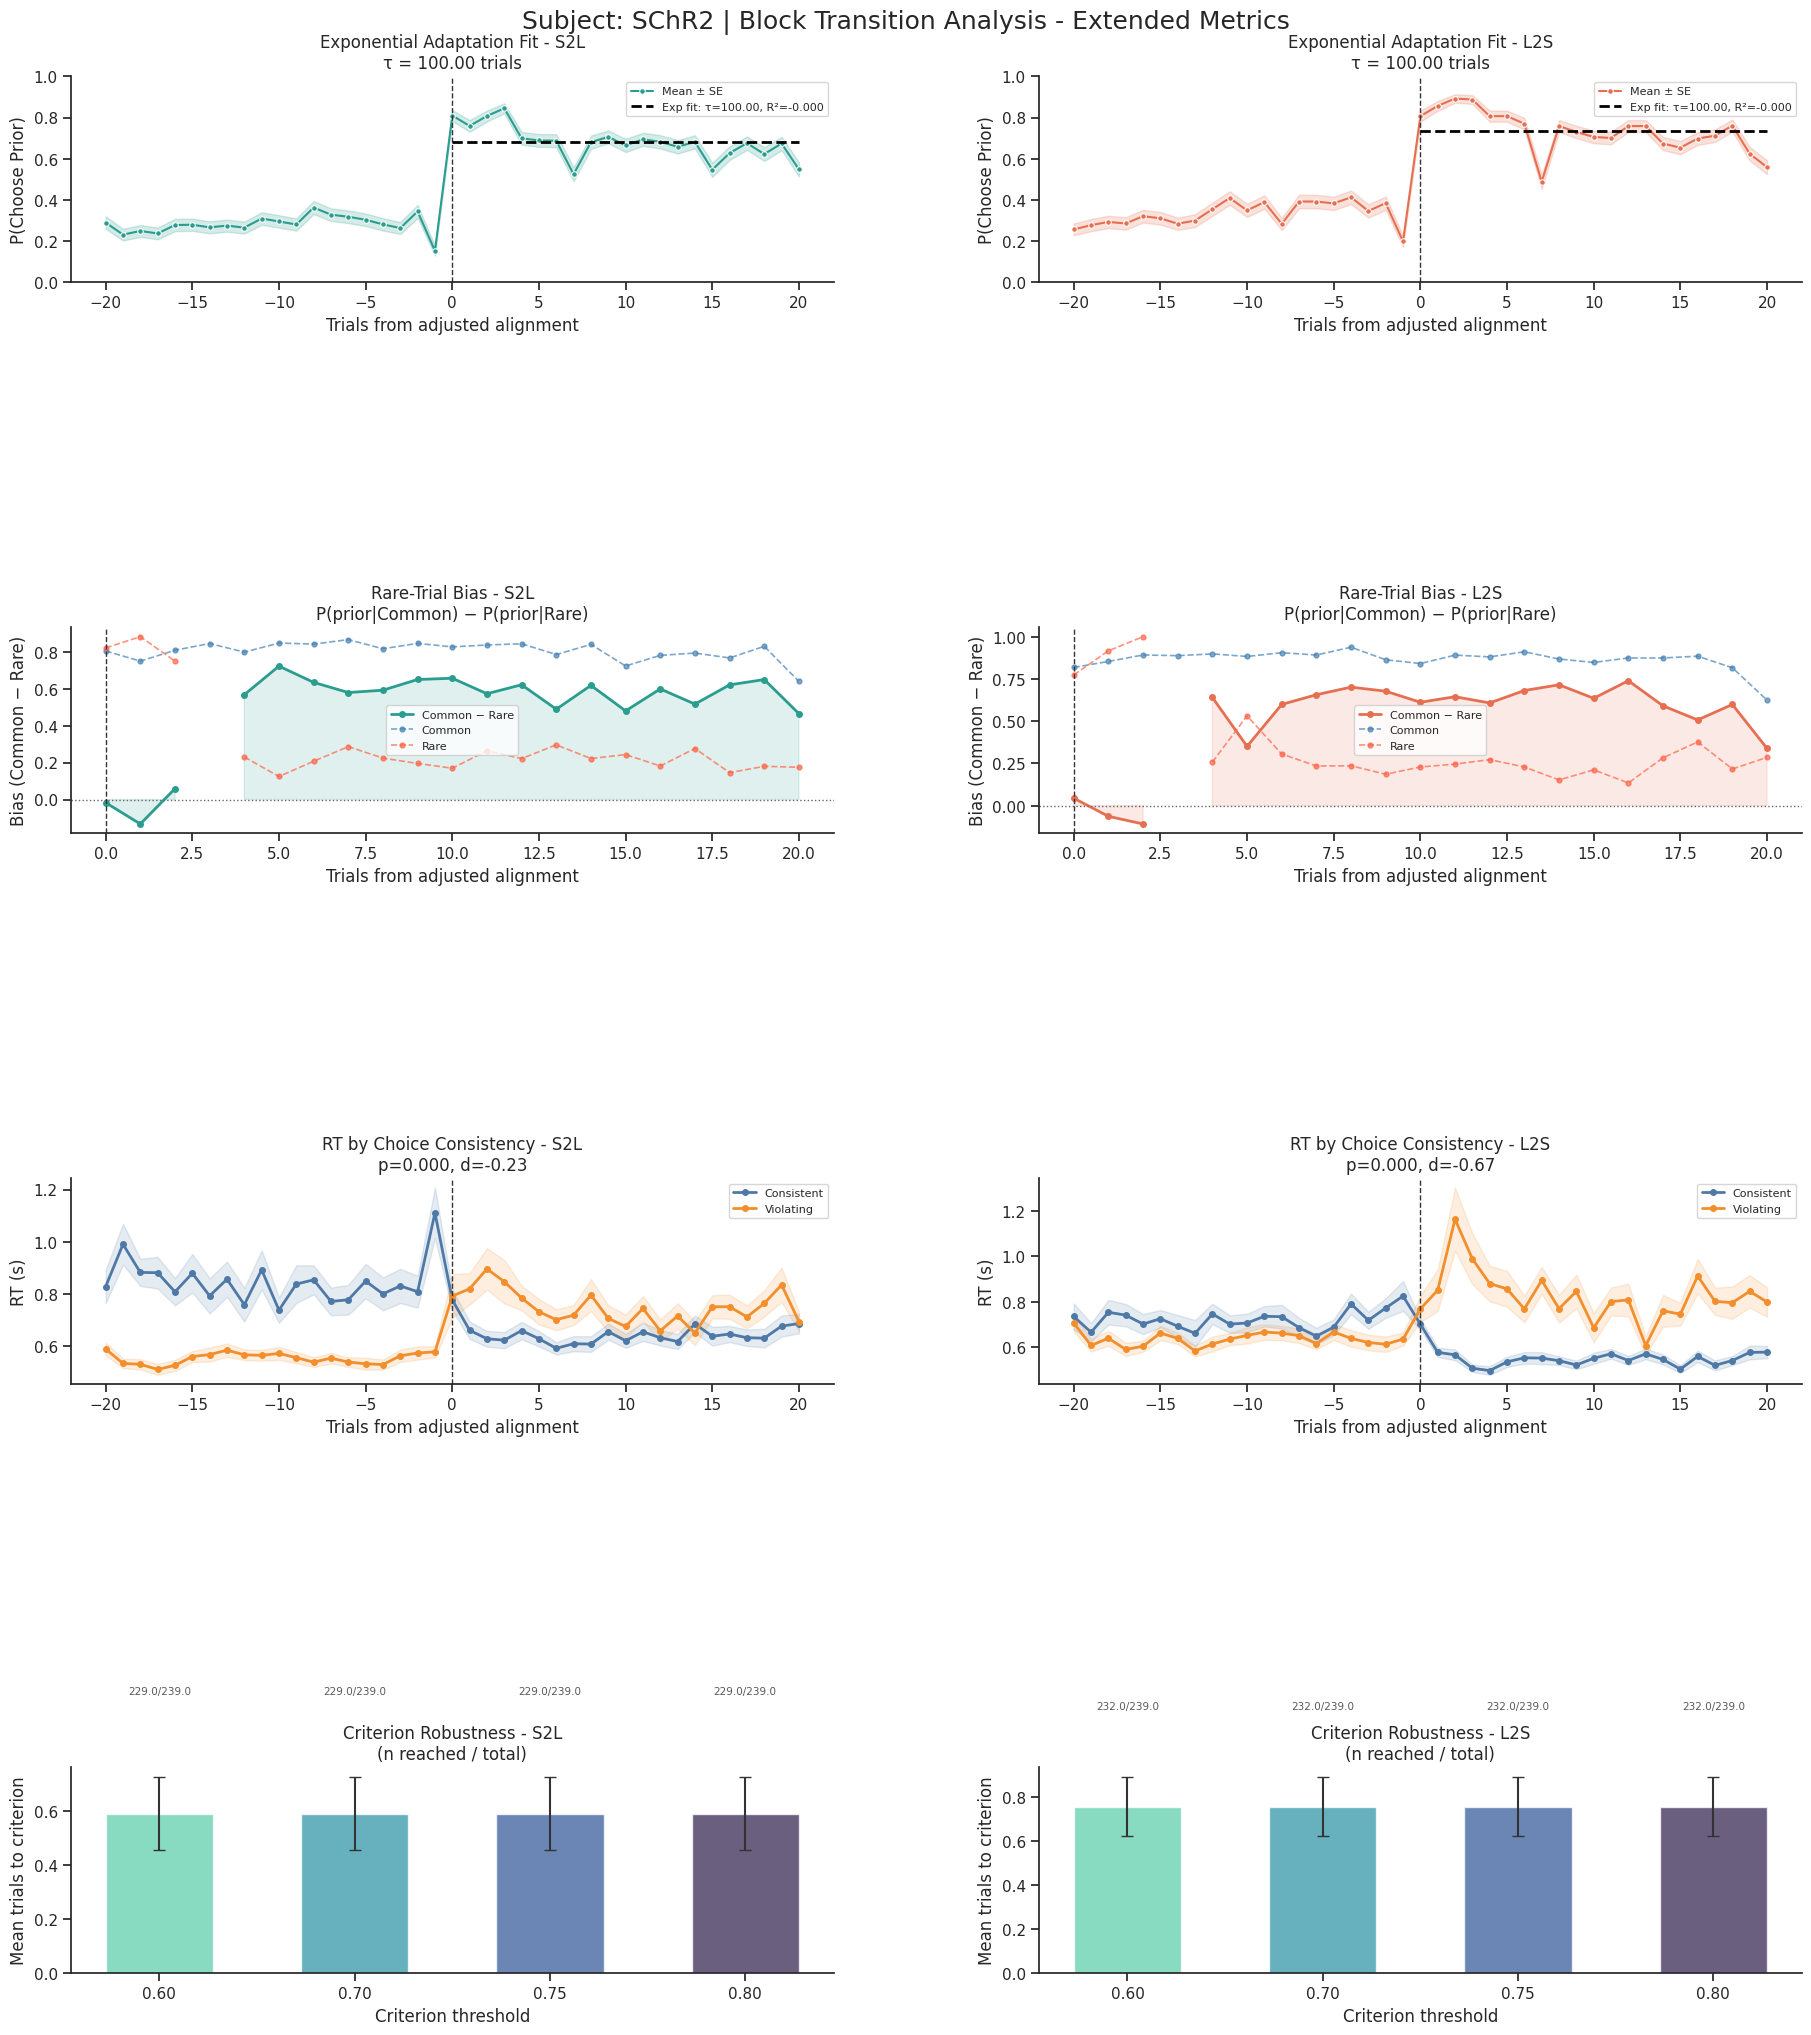

Saved extra figure to: transition_adaptation_extra.png

Window summary, raw unsmoothed data:
  trans_type    n       pre     early      late  delta_early  delta_late
0        L2S  239  0.373615  0.826046  0.684236     0.471921    0.317538
1        S2L  239  0.290984  0.749435  0.620582     0.458913    0.333505

Trial-to-criterion summary (primary criterion):
            count      mean       std  min  25%  50%  75%   max
trans_type                                                     
L2S         232.0  0.758621  2.041223  0.0  0.0  0.0  0.0  16.0
S2L         229.0  0.589520  2.040613  0.0  0.0  0.0  0.0  19.0

Exponential τ fits:
  S2L: τ=100.000 trials, a=0.000, b=0.681, R²=-0.0000
  L2S: τ=100.000 trials, a=0.000, b=0.734, R²=-0.0000

Criterion robustness summary:
trans_type  criterion  n_reached  total  median     mean
       L2S       0.60        232    232     0.0 0.758621
       L2S       0.70        232    232     0.0 0.758621
       L2S       0.75        232    232     0.0 0.75

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
import json
from matplotlib.gridspec import GridSpec
from scipy.optimize import curve_fit
from scipy.stats import ttest_ind

# ===============================
# SETTINGS
# ===============================
WINDOW = 1
FIRST_BLOCK_TRIALS_FORCED_COMMON = 4
TRIAL_RANGE = 20
RESET_SMOOTH_AT_TRANSITION = False
TRANSITION_LINE_X = 0
SAVE_FIGURE_PATH = "/home/ihsan/Desktop/data/Georgia_Tech/2AFC/Figures_behavior/Mega_pdf/transition_adaptation_summary.pdf"
SAVE_FIGURE_PATH_2 = "/home/ihsan/Desktop/data/Georgia_Tech/2AFC/Figures_behavior/Mega_pdf/transition_adaptation_extra.pdf"

CRITERION_LEVELS = [0.6, 0.7, 0.75, 0.8]   # robustness check thresholds
CRITERION_MAIN = 0.7                          # primary threshold

NEGATIVE_LICK_ARRAY_COLUMNS = ['all_lick_reaction_times', 'all_lick_start_times_from_choice']
NEGATIVE_LICK_DETAIL_KEYS = ['reaction_time', 'start_time_from_choice']
RT_NEGATIVE_LICK_FLAG = 'rt_excluded_negative_lick_array'


def _load_lick_array_value(value):
    if value is None:
        return []
    if isinstance(value, float) and np.isnan(value):
        return []
    if isinstance(value, str):
        text = value.strip()
        if not text or text.lower() in {'nan', 'none', 'null'}:
            return []
        try:
            return json.loads(text)
        except (json.JSONDecodeError, TypeError):
            try:
                return ast.literal_eval(text)
            except (ValueError, SyntaxError):
                return []
    return value


def _iter_relative_lick_times(value):
    value = _load_lick_array_value(value)
    if isinstance(value, dict):
        for key in NEGATIVE_LICK_DETAIL_KEYS:
            if key in value:
                yield value[key]
        return
    if isinstance(value, (list, tuple, np.ndarray)):
        for item in value:
            yield from _iter_relative_lick_times(item)
        return
    yield value


def has_negative_lick_time(value):
    for item in _iter_relative_lick_times(value):
        if item is None:
            continue
        try:
            if pd.notna(item) and float(item) < 0:
                return True
        except (TypeError, ValueError):
            continue
    return False


def get_negative_lick_array_mask(df):
    mask = pd.Series(False, index=df.index)
    columns = [column for column in NEGATIVE_LICK_ARRAY_COLUMNS if column in df.columns]

    for column in columns:
        mask = mask | df[column].apply(has_negative_lick_time)

    if not columns and 'all_lick_details' in df.columns:
        mask = mask | df['all_lick_details'].apply(has_negative_lick_time)

    return mask


def add_rt_exclusion_flag(df):
    df = df.copy()
    df[RT_NEGATIVE_LICK_FLAG] = get_negative_lick_array_mask(df)
    return df


def get_valid_reaction_time(row):
    excluded = row.get(RT_NEGATIVE_LICK_FLAG, False)
    if pd.notna(excluded) and bool(excluded):
        return np.nan
    return row.get('lick_reaction_time', np.nan)


sns.set_theme(style="ticks", context="notebook", rc={"axes.grid": False})


# ===============================
# HELPERS
# ===============================

def clean_axis(ax, ylim=None):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.axvline(TRANSITION_LINE_X, ls="--", color="0.2", lw=1)
    if ylim is not None:
        ax.set_ylim(*ylim)


def format_subject_label(df):
    if "subject" not in df.columns:
        return "Unknown"

    subjects = sorted(df["subject"].dropna().astype(str).unique())
    if not subjects:
        return "Unknown"
    if len(subjects) <= 4:
        return ", ".join(subjects)
    return f"{len(subjects)} subjects"


def exp_func(x, a, tau, b):
    """Saturating exponential: a * (1 - exp(-x / tau)) + b"""
    return a * (1 - np.exp(-x / tau)) + b


def fit_exponential(df_t, trans_type):
    """
    Fit a saturating exponential to the post-alignment P(prior) curve.
    Returns (tau, a, b, x_fit, y_fit, r2) or None on failure.
    """
    d = df_t[(df_t["trans_type"] == trans_type) & (df_t["rel_trial"] >= 0)]
    if d.empty:
        return None

    curve = (
        d.groupby("rel_trial")["prior_choice_smooth"]
        .mean()
        .reset_index()
        .sort_values("rel_trial")
    )

    x = curve["rel_trial"].values.astype(float)
    y = curve["prior_choice_smooth"].values

    valid = ~np.isnan(y)
    x, y = x[valid], y[valid]

    if len(x) < 4:
        return None

    try:
        p0 = [0.4, 5.0, y[0]]
        bounds = ([0, 0.1, 0], [1, 100, 1])
        popt, _ = curve_fit(exp_func, x, y, p0=p0, bounds=bounds, maxfev=8000)
        a, tau, b = popt

        y_pred = exp_func(x, *popt)
        ss_res = np.sum((y - y_pred) ** 2)
        ss_tot = np.sum((y - y.mean()) ** 2)
        r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

        x_fit = np.linspace(x.min(), x.max(), 200)
        y_fit = exp_func(x_fit, *popt)

        return tau, a, b, x_fit, y_fit, r2

    except RuntimeError:
        return None


def prepare_data(df):
    df = df.copy()
    if RT_NEGATIVE_LICK_FLAG not in df.columns:
        df = add_rt_exclusion_flag(df)

    if "trial_num" not in df.columns:
        df["_trial_order"] = df.groupby("session_idx", sort=False).cumcount() + 1

    df["block_type"] = pd.to_numeric(df["block_type"], errors="coerce")
    df["trial_type"] = pd.to_numeric(df["trial_type"], errors="coerce")

    if "warm_up" in df.columns:
        warm = pd.to_numeric(df["warm_up"], errors="coerce").fillna(0)
        df = df[warm == 0].copy()

    df = df[df["block_type"].isin([1, 2])].copy()

    valid_lick = df["lick_side"].isin(["Left", "Right"])
    if "Contingency" in df.columns:
        contingency_text = df["Contingency"].astype(str)
    else:
        contingency_text = pd.Series("Normal - Short/Left", index=df.index)

    normal = contingency_text.str.contains("Normal - Short/Left", na=False)
    reverse = contingency_text.str.contains("Reverse - Long/Left", na=False)
    unknown = valid_lick & ~(normal | reverse)
    if unknown.any():
        print(f"Warning: defaulting {unknown.sum()} unknown-contingency rows to P(Choose Right).")
        normal = normal | unknown

    df["target_choice"] = np.nan
    # target_choice is the long-associated response: Right in normal, Left in reverse.
    idx = valid_lick & normal
    df.loc[idx, "target_choice"] = (df.loc[idx, "lick_side"] == "Right").astype(float)

    idx = valid_lick & reverse
    df.loc[idx, "target_choice"] = (df.loc[idx, "lick_side"] == "Left").astype(float)

    return df


def mask_early_block_rare_trials(sdf, n_first=FIRST_BLOCK_TRIALS_FORCED_COMMON):
    """Set rare labels in the first n trials of each block to NaN for analysis."""
    sdf = sdf.copy()
    block_run = sdf["block_type"].ne(sdf["block_type"].shift()).cumsum()
    sdf["trial_in_block"] = sdf.groupby(block_run, sort=False).cumcount() + 1
    raw_rare = (
        (sdf["block_type"].eq(1) & sdf["trial_type"].eq(2)) |
        (sdf["block_type"].eq(2) & sdf["trial_type"].eq(1))
    )
    early_rare = raw_rare & sdf["trial_in_block"].le(n_first)
    sdf["analysis_trial_type"] = sdf["trial_type"].mask(early_rare)
    sdf["analysis_is_rare"] = raw_rare.astype(float).mask(early_rare)
    sdf["early_block_rare_masked"] = early_rare
    return sdf


def is_rare_trial(row):
    if "analysis_is_rare" in row.index:
        return row.get("analysis_is_rare") == 1
    return ((row["block_type"] == 1 and row["trial_type"] == 2) or
            (row["block_type"] == 2 and row["trial_type"] == 1))


def get_adjusted_alignment_index(sdf, formal_switch_idx, prev_block):
    """
    If the previous block ends with one or more rare trials, align to the
    first trial in that terminal rare run. Otherwise align to the formal switch.
    """
    last_prev_idx = formal_switch_idx - 1
    if last_prev_idx < 0 or not is_rare_trial(sdf.loc[last_prev_idx]):
        return formal_switch_idx

    align_idx = last_prev_idx
    while align_idx - 1 >= 0:
        prev_row = sdf.loc[align_idx - 1]
        if prev_row["block_type"] != prev_block or not is_rare_trial(prev_row):
            break
        align_idx -= 1

    return align_idx


def extract_transitions(df):
    trans_data = []
    trans_id = 0

    order_col = "trial_num" if "trial_num" in df.columns else "_trial_order"

    for sess, sdf in df.groupby("session_idx", sort=False):
        sdf = sdf.sort_values(order_col).reset_index(drop=True)
        sdf = mask_early_block_rare_trials(sdf)

        block_change = sdf["block_type"] != sdf["block_type"].shift(1)
        transitions = sdf.index[
            block_change & sdf["block_type"].shift(1).notna()
        ].tolist()

        for t_idx in transitions:
            prev_block = sdf.loc[t_idx - 1, "block_type"]
            curr_block = sdf.loc[t_idx, "block_type"]

            if prev_block == 1 and curr_block == 2:
                t_type = "S2L"
            elif prev_block == 2 and curr_block == 1:
                t_type = "L2S"
            else:
                continue

            trans_id += 1

            align_idx = get_adjusted_alignment_index(sdf, t_idx, prev_block)
            alignment_shift = t_idx - align_idx

            for i in range(align_idx - TRIAL_RANGE, align_idx + TRIAL_RANGE + 1):
                if i < 0 or i >= len(sdf):
                    continue

                row = sdf.loc[i]
                rel = i - align_idx
                choice_long = row["target_choice"]

                if curr_block == 2:
                    prior_choice = choice_long
                else:
                    prior_choice = 1 - choice_long

                analysis_is_rare = row.get("analysis_is_rare", np.nan)
                if pd.isna(analysis_is_rare):
                    trial_class = np.nan
                elif analysis_is_rare == 0:
                    trial_class = "Common"
                else:
                    trial_class = "Rare"

                # Prior-consistent = chose the new block's prior; prior-violating = did not
                is_consistent = (prior_choice == 1.0) if not pd.isna(prior_choice) else np.nan
                rt_val = get_valid_reaction_time(row)

                trans_data.append({
                    "session_idx": sess,
                    "trans_id": trans_id,
                    "trans_type": t_type,
                    "old_block": prev_block,
                    "new_block": curr_block,
                    "formal_switch_rel_trial": alignment_shift,
                    "alignment_shift": alignment_shift,
                    "aligned_on_terminal_rare": alignment_shift > 0,
                    "rel_trial": rel,
                    "abs_trial_order": row[order_col],
                    "block_type": row["block_type"],
                    "trial_type": row["trial_type"],
                    "choice_long": choice_long,
                    "prior_choice": prior_choice,
                    "trial_class": trial_class,
                    "rt": rt_val,
                    "choice_consistent": is_consistent
                })

    return pd.DataFrame(trans_data)


def add_causal_smooth(df, cols):
    out = df.copy()
    out["_orig_idx"] = np.arange(len(out))
    out = out.sort_values(["trans_id", "rel_trial"])

    if RESET_SMOOTH_AT_TRANSITION:
        out["_smooth_phase"] = np.where(out["rel_trial"] < 0, "pre", "post")
        group_cols = ["trans_id", "_smooth_phase"]
    else:
        group_cols = ["trans_id"]

    for col in cols:
        smooth_col = f"{col}_smooth"
        out[smooth_col] = out.groupby(group_cols, sort=False)[col].transform(
            lambda x: x.rolling(WINDOW, min_periods=1).mean()
        )
        out.loc[out[col].isna(), smooth_col] = np.nan

    out = out.sort_values("_orig_idx").drop(
        columns=["_orig_idx", "_smooth_phase"],
        errors="ignore"
    )

    return out


def compute_window_metrics(df):
    metrics = []

    windows = {
        "pre": (-10, -1),
        "early": (0, 5),
        "late": (6, TRIAL_RANGE)
    }

    for trans_id, g in df.groupby("trans_id"):
        row = {
            "trans_id": trans_id,
            "trans_type": g["trans_type"].iloc[0],
            "session_idx": g["session_idx"].iloc[0]
        }

        for name, (lo, hi) in windows.items():
            row[name] = g.loc[g["rel_trial"].between(lo, hi), "prior_choice"].mean()

        row["delta_early"] = row["early"] - row["pre"]
        row["delta_late"] = row["late"] - row["pre"]

        metrics.append(row)

    metrics = pd.DataFrame(metrics)

    summary = metrics.groupby("trans_type").agg(
        n=("trans_id", "count"),
        pre=("pre", "mean"),
        early=("early", "mean"),
        late=("late", "mean"),
        delta_early=("delta_early", "mean"),
        delta_late=("delta_late", "mean")
    ).reset_index()

    return metrics, summary


def compute_trial_to_criterion(df_t, criterion=CRITERION_MAIN):
    rows = []

    for trans_id, g in df_t.groupby("trans_id"):
        post = g[g["rel_trial"] >= 0].sort_values("rel_trial")
        hit = post[post["prior_choice_smooth"] >= criterion]

        rows.append({
            "trans_id": trans_id,
            "trans_type": g["trans_type"].iloc[0],
            "trial_to_criterion": hit["rel_trial"].iloc[0] if len(hit) else np.nan
        })

    return pd.DataFrame(rows)


def compute_multi_criterion_ttc(df_t, criterion_levels=CRITERION_LEVELS):
    """
    Compute trial-to-criterion for multiple threshold values.
    Returns a long-form DataFrame with columns: trans_type, criterion, trial_to_criterion.
    """
    rows = []
    for crit in criterion_levels:
        ttc = compute_trial_to_criterion(df_t, criterion=crit)
        ttc["criterion"] = crit
        rows.append(ttc)
    return pd.concat(rows, ignore_index=True)


def compute_rare_bias(df_t):
    """
    rare_bias = P_prior(common) - P_prior(rare) per transition, per rel_trial.
    Returns trial-level and summary DataFrames.
    """
    post = df_t[df_t["rel_trial"] >= 0].copy()

    trial_level = (
        post.groupby(["trans_type", "rel_trial", "trial_class"])["prior_choice"]
        .mean()
        .reset_index()
    )

    pivot = trial_level.pivot_table(
        index=["trans_type", "rel_trial"],
        columns="trial_class",
        values="prior_choice"
    ).reset_index()

    if "Common" in pivot.columns and "Rare" in pivot.columns:
        pivot["rare_bias"] = pivot["Common"] - pivot["Rare"]
    else:
        pivot["rare_bias"] = np.nan

    return pivot


def format_summary_box(summary, ttc, df_t, criterion=CRITERION_MAIN):
    counts = df_t.groupby("trans_type")["trans_id"].nunique()
    total = df_t["trans_id"].nunique()

    alignment_info = df_t[["trans_id", "trans_type", "alignment_shift"]].drop_duplicates()
    adjusted_counts = alignment_info[alignment_info["alignment_shift"] > 0].groupby("trans_type")["trans_id"].count()

    lines = [
        "Analysis Summary",
        f"Transitions: total={total}, S2L={counts.get('S2L', 0)}, L2S={counts.get('L2S', 0)}",
        f"Terminal-rare adjusted: S2L={adjusted_counts.get('S2L', 0)}, L2S={adjusted_counts.get('L2S', 0)}",
        f"Smoothing: causal, window={WINDOW}, reset={RESET_SMOOTH_AT_TRANSITION}",
        "rel_trial=0: adjusted alignment event",
        "If terminal previous-block rare trials exist, alignment starts at the first one.",
        "Otherwise rel_trial=0 is the first new-block trial.",
        "Alignment boundary shown at x=-0.5",
        "",
        "Window means, raw data:",
    ]

    for _, r in summary.iterrows():
        lines.append(
            f"{r['trans_type']}: pre={r['pre']:.3f}, early={r['early']:.3f}, late={r['late']:.3f}"
        )
        lines.append(
            f"    delta early={r['delta_early']:+.3f}, delta late={r['delta_late']:+.3f}"
        )

    lines.append("")
    lines.append(f"Trial to criterion >= {criterion:.2f}:")

    for t in ["S2L", "L2S"]:
        d_all = ttc[ttc["trans_type"] == t]
        d_hit = d_all["trial_to_criterion"].dropna()

        if len(d_hit):
            lines.append(
                f"{t}: median={d_hit.median():.1f}, mean={d_hit.mean():.1f}, "
                f"reached={len(d_hit)}/{len(d_all)}"
            )
        else:
            lines.append(f"{t}: reached=0/{len(d_all)}")

    return "\n".join(lines)


def setup_heatmap_axis(ax, pivot):
    cols = pivot.columns.to_numpy()
    tick_values = [v for v in range(-TRIAL_RANGE, TRIAL_RANGE + 1, 5) if v in cols]
    tick_positions = [np.where(cols == v)[0][0] + 0.5 for v in tick_values]

    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_values, rotation=0)

    if 0 in cols:
        x0 = np.where(cols == 0)[0][0]
        ax.axvline(x0, ls="--", color="white", lw=1.2)


# ===============================
# FIGURE 1: Original panels
# ===============================

def plot_full_analysis(df_t, metrics, summary, ttc, save_path=SAVE_FIGURE_PATH, criterion=CRITERION_MAIN, subject_label="Unknown"):
    fig = plt.figure(figsize=(18, 24), constrained_layout=True)

    gs = GridSpec(
        5, 6,
        figure=fig,
        height_ratios=[1, 1, 1, 1.25, 1.15],
        hspace=0.45,
        wspace=0.45
    )

    axes = {
        "choice_s2l": fig.add_subplot(gs[0, 0:2]),
        "choice_l2s": fig.add_subplot(gs[0, 2:4]),
        "pooled": fig.add_subplot(gs[0, 4:6]),
        "prior_s2l": fig.add_subplot(gs[1, 0:2]),
        "prior_l2s": fig.add_subplot(gs[1, 2:4]),
        "rt": fig.add_subplot(gs[1, 4:6]),
        "common_s2l": fig.add_subplot(gs[2, 0:3]),
        "common_l2s": fig.add_subplot(gs[2, 3:6]),
        "heat_s2l": fig.add_subplot(gs[3, 0:3]),
        "heat_l2s": fig.add_subplot(gs[3, 3:6]),
        "windows": fig.add_subplot(gs[4, 0:2]),
        "ttc": fig.add_subplot(gs[4, 2:4]),
        "summary": fig.add_subplot(gs[4, 4:6]),
    }

    colors = {"S2L": "#2a9d8f", "L2S": "#e76f51"}

    for t, ax_key in zip(["S2L", "L2S"], ["choice_s2l", "choice_l2s"]):
        ax = axes[ax_key]
        d = df_t[df_t["trans_type"] == t]
        n = d["trans_id"].nunique()

        sns.lineplot(
            data=d,
            x="rel_trial",
            y="choice_long_smooth",
            errorbar="se",
            color=colors[t],
            marker="o",
            markersize=4,
            ax=ax
        )

        ax.set_title(f"P(Long-Associated Response) - {t}, n={n}")
        ax.set_ylabel("P(Long-Associated Response)")
        ax.set_xlabel("")
        clean_axis(ax, ylim=(0, 1))

    sns.lineplot(
        data=df_t,
        x="rel_trial",
        y="prior_choice_smooth",
        errorbar="se",
        color="0.25",
        marker="o",
        markersize=4,
        ax=axes["pooled"]
    )
    axes["pooled"].set_title("Prior Adaptation - All")
    axes["pooled"].set_ylabel("P(Choose Prior)")
    axes["pooled"].set_xlabel("")
    clean_axis(axes["pooled"], ylim=(0, 1))

    for t, ax_key in zip(["S2L", "L2S"], ["prior_s2l", "prior_l2s"]):
        ax = axes[ax_key]
        d = df_t[df_t["trans_type"] == t]

        sns.lineplot(
            data=d,
            x="rel_trial",
            y="prior_choice_smooth",
            errorbar="se",
            color=colors[t],
            marker="o",
            markersize=4,
            ax=ax
        )

        ax.set_title(f"P(Choose New Block Prior) - {t}")
        ax.set_ylabel("P(Choose Prior)")
        ax.set_xlabel("")
        clean_axis(ax, ylim=(0, 1))

    sns.lineplot(
        data=df_t,
        x="rel_trial",
        y="rt_smooth",
        errorbar="se",
        color="0.25",
        marker="o",
        markersize=4,
        ax=axes["rt"]
    )
    axes["rt"].set_title("Reaction Time")
    axes["rt"].set_ylabel("RT")
    axes["rt"].set_xlabel("")
    clean_axis(axes["rt"])

    for t, ax_key in zip(["S2L", "L2S"], ["common_s2l", "common_l2s"]):
        ax = axes[ax_key]
        d = df_t[df_t["trans_type"] == t]

        sns.lineplot(
            data=d,
            x="rel_trial",
            y="prior_choice_smooth",
            hue="trial_class",
            hue_order=["Common", "Rare"],
            errorbar="se",
            marker="o",
            markersize=4,
            ax=ax
        )

        ax.set_title(f"Common vs Rare - {t}")
        ax.set_ylabel("P(Choose New Block Prior)")
        ax.set_xlabel("Trials from adjusted alignment")
        clean_axis(ax, ylim=(0, 1))

    for t, ax_key in zip(["S2L", "L2S"], ["heat_s2l", "heat_l2s"]):
        ax = axes[ax_key]
        d = df_t[df_t["trans_type"] == t]

        pivot = d.pivot_table(
            index="trans_id",
            columns="rel_trial",
            values="prior_choice_smooth",
            aggfunc="mean"
        )

        if pivot.empty:
            ax.set_title(f"Transition Heatmap - {t}")
            ax.axis("off")
            continue

        pre = pivot.loc[:, pivot.columns < 0].mean(axis=1)
        post = pivot.loc[:, pivot.columns >= 5].mean(axis=1)
        order = (post - pre).sort_values().index
        pivot = pivot.loc[order]

        sns.heatmap(
            pivot,
            ax=ax,
            cmap="viridis",
            vmin=0,
            vmax=1,
            cbar=(t == "L2S"),
            cbar_kws={"label": "P(Choose Prior)"}
        )

        setup_heatmap_axis(ax, pivot)
        ax.set_title(f"Transition Heatmap - {t}")
        ax.set_xlabel("rel_trial")
        ax.set_ylabel("Transition ID")
        ax.grid(False)

    long = metrics.melt(
        id_vars=["trans_id", "trans_type"],
        value_vars=["pre", "early", "late"],
        var_name="window",
        value_name="prior_choice"
    )

    long["window"] = pd.Categorical(
        long["window"],
        categories=["pre", "early", "late"],
        ordered=True
    )

    sns.pointplot(
        data=long,
        x="window",
        y="prior_choice",
        hue="trans_type",
        errorbar="se",
        dodge=0.25,
        ax=axes["windows"]
    )

    axes["windows"].set_title("Prior Choice by Window")
    axes["windows"].set_xlabel("")
    axes["windows"].set_ylabel("P(Choose Prior)")
    axes["windows"].set_ylim(0, 1)
    axes["windows"].set_xticklabels(["Pre", "Early Post", "Late Post"])
    axes["windows"].grid(False)
    axes["windows"].spines["top"].set_visible(False)
    axes["windows"].spines["right"].set_visible(False)

    d_ttc = ttc.dropna(subset=["trial_to_criterion"])

    if d_ttc.empty:
        axes["ttc"].text(
            0.5, 0.5, "No transitions reached criterion",
            ha="center", va="center",
            transform=axes["ttc"].transAxes
        )
    else:
        sns.boxplot(
            data=d_ttc,
            x="trans_type",
            y="trial_to_criterion",
            showfliers=False,
            color="white",
            ax=axes["ttc"]
        )

        sns.stripplot(
            data=d_ttc,
            x="trans_type",
            y="trial_to_criterion",
            alpha=0.35,
            jitter=0.25,
            size=3,
            ax=axes["ttc"]
        )

    axes["ttc"].set_title("Trials to Criterion")
    axes["ttc"].set_xlabel("Transition")
    axes["ttc"].set_ylabel(f"First trial P(prior) >= {criterion:.2f}")
    axes["ttc"].grid(False)
    axes["ttc"].spines["top"].set_visible(False)
    axes["ttc"].spines["right"].set_visible(False)

    axes["summary"].axis("off")
    summary_text = format_summary_box(summary, ttc, df_t, criterion=criterion)

    axes["summary"].text(
        0.02, 0.98, summary_text,
        transform=axes["summary"].transAxes,
        ha="left", va="top",
        fontsize=10, family="monospace",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="0.35",
            linewidth=1.0
        )
    )

    fig.suptitle(f"Subject: {subject_label} | Block Transition Adaptation Analysis", fontsize=18, y=1.01)
    fig.savefig(save_path, dpi=600, bbox_inches="tight")
    plt.show()
    print(f"Saved figure to: {save_path}")


# ===============================
# FIGURE 2: New panels
# ===============================

def plot_extra_analysis(df_t, save_path=SAVE_FIGURE_PATH_2, subject_label="Unknown"):
    """
    4 new panels:
      Row 0: Exponential fit (τ) for S2L and L2S
      Row 1: Rare-bias metric
      Row 2: RT split by choice consistency
      Row 3: Criterion robustness (multi-threshold TTC)
    """
    colors = {"S2L": "#2a9d8f", "L2S": "#e76f51"}

    fig = plt.figure(figsize=(18, 20), constrained_layout=True)

    gs = GridSpec(
        4, 6,
        figure=fig,
        height_ratios=[1, 1, 1, 1],
        hspace=0.5,
        wspace=0.45
    )

    ax_exp_s2l   = fig.add_subplot(gs[0, 0:3])
    ax_exp_l2s   = fig.add_subplot(gs[0, 3:6])
    ax_bias_s2l  = fig.add_subplot(gs[1, 0:3])
    ax_bias_l2s  = fig.add_subplot(gs[1, 3:6])
    ax_rt_s2l    = fig.add_subplot(gs[2, 0:3])
    ax_rt_l2s    = fig.add_subplot(gs[2, 3:6])
    ax_crit_s2l  = fig.add_subplot(gs[3, 0:3])
    ax_crit_l2s  = fig.add_subplot(gs[3, 3:6])

    # ------------------------------------------------------------------
    # Row 0: Exponential fit
    # ------------------------------------------------------------------
    for t, ax in zip(["S2L", "L2S"], [ax_exp_s2l, ax_exp_l2s]):
        d = df_t[(df_t["trans_type"] == t) & (df_t["rel_trial"] >= 0)]
        curve = (
            d.groupby("rel_trial")["prior_choice_smooth"]
            .mean()
            .reset_index()
            .sort_values("rel_trial")
        )

        sns.lineplot(
            data=df_t[(df_t["trans_type"] == t)],
            x="rel_trial",
            y="prior_choice_smooth",
            errorbar="se",
            color=colors[t],
            ax=ax,
            marker="o",
            markersize=4,
            label="Mean ± SE",
            zorder=2
        )

        fit_result = fit_exponential(df_t, t)
        tau_str = ""

        if fit_result is not None:
            tau, a, b, x_fit, y_fit, r2 = fit_result
            ax.plot(x_fit, y_fit, color="black", lw=2, ls="--",
                    label=f"Exp fit: τ={tau:.2f}, R²={r2:.3f}", zorder=3)
            tau_str = f"τ = {tau:.2f} trials"

        ax.set_title(f"Exponential Adaptation Fit - {t}\n{tau_str}")
        ax.set_ylabel("P(Choose Prior)")
        ax.set_xlabel("Trials from adjusted alignment")
        ax.legend(fontsize=8)
        clean_axis(ax, ylim=(0, 1))

    # ------------------------------------------------------------------
    # Row 1: Rare-bias metric
    # ------------------------------------------------------------------
    bias_df = compute_rare_bias(df_t)

    for t, ax in zip(["S2L", "L2S"], [ax_bias_s2l, ax_bias_l2s]):
        d = bias_df[bias_df["trans_type"] == t].sort_values("rel_trial")

        if "rare_bias" in d.columns and not d["rare_bias"].isna().all():
            ax.plot(d["rel_trial"], d["rare_bias"],
                    color=colors[t], lw=2, marker="o", markersize=4, label="Common − Rare")
            ax.fill_between(d["rel_trial"], 0, d["rare_bias"],
                            alpha=0.15, color=colors[t])
            ax.axhline(0, color="0.4", lw=1, ls=":")

            if "Common" in d.columns and "Rare" in d.columns:
                ax.plot(d["rel_trial"], d["Common"],
                        color="steelblue", lw=1.2, ls="--", marker="o", markersize=3.5, alpha=0.7, label="Common")
                ax.plot(d["rel_trial"], d["Rare"],
                        color="tomato", lw=1.2, ls="--", marker="o", markersize=3.5, alpha=0.7, label="Rare")

            ax.legend(fontsize=8)
        else:
            ax.text(0.5, 0.5, "Insufficient data",
                    ha="center", va="center", transform=ax.transAxes)

        ax.set_title(f"Rare-Trial Bias - {t}\nP(prior|Common) − P(prior|Rare)")
        ax.set_ylabel("Bias (Common − Rare)")
        ax.set_xlabel("Trials from adjusted alignment")
        clean_axis(ax)

    # ------------------------------------------------------------------
    # Row 2: RT split by choice consistency (consistent vs violating)
    # ------------------------------------------------------------------
    # Label each trial as consistent (chose new block prior) or violating
    df_rt = df_t.copy()
    df_rt["consistency"] = df_rt["choice_consistent"].map(
        {1.0: "Consistent", 0.0: "Violating"}
    )
    df_rt = df_rt[df_rt["consistency"].notna() & df_rt["rt"].notna()]

    for t, ax in zip(["S2L", "L2S"], [ax_rt_s2l, ax_rt_l2s]):
        d = df_rt[df_rt["trans_type"] == t]

        if d.empty:
            ax.text(0.5, 0.5, "No RT data", ha="center", va="center",
                    transform=ax.transAxes)
        else:
            # Smooth RT per trans_id, consistency class, rel_trial
            rt_curve = (
                d.groupby(["consistency", "rel_trial"])["rt"]
                .agg(mean="mean", sem=lambda x: x.sem())
                .reset_index()
            )

            for cons, grp in rt_curve.groupby("consistency"):
                c = "#4e79a7" if cons == "Consistent" else "#f28e2b"
                ax.plot(grp["rel_trial"], grp["mean"], color=c, lw=2, marker="o", markersize=4, label=cons)
                ax.fill_between(
                    grp["rel_trial"],
                    grp["mean"] - grp["sem"],
                    grp["mean"] + grp["sem"],
                    alpha=0.15, color=c
                )

            # Stats: post-alignment difference
            post = d[d["rel_trial"] >= 0]
            cons_rt = post.loc[post["consistency"] == "Consistent", "rt"].dropna()
            viol_rt = post.loc[post["consistency"] == "Violating", "rt"].dropna()

            stat_str = ""
            if len(cons_rt) > 1 and len(viol_rt) > 1:
                _, p = ttest_ind(cons_rt, viol_rt)
                d_effect = (cons_rt.mean() - viol_rt.mean()) / (
                    pd.concat([cons_rt, viol_rt]).std() + 1e-9
                )
                stat_str = f"p={p:.3f}, d={d_effect:.2f}"

            ax.legend(fontsize=8)
            ax.set_title(f"RT by Choice Consistency - {t}\n{stat_str}")

        ax.set_ylabel("RT (s)")
        ax.set_xlabel("Trials from adjusted alignment")
        clean_axis(ax)

    # ------------------------------------------------------------------
    # Row 3: Criterion robustness check
    # ------------------------------------------------------------------
    multi_ttc = compute_multi_criterion_ttc(df_t, criterion_levels=CRITERION_LEVELS)

    palette = sns.color_palette("mako_r", n_colors=len(CRITERION_LEVELS))
    crit_color = {c: palette[i] for i, c in enumerate(CRITERION_LEVELS)}

    for t, ax in zip(["S2L", "L2S"], [ax_crit_s2l, ax_crit_l2s]):
        d = multi_ttc[multi_ttc["trans_type"] == t]

        summary_rows = []
        for crit in CRITERION_LEVELS:
            vals = d.loc[d["criterion"] == crit, "trial_to_criterion"].dropna()
            if len(vals):
                summary_rows.append({
                    "criterion": crit,
                    "median": vals.median(),
                    "mean": vals.mean(),
                    "sem": vals.sem(),
                    "n": len(vals),
                    "total": len(d[d["criterion"] == crit])
                })

        if summary_rows:
            sr = pd.DataFrame(summary_rows)

            # Bar plot of mean TTC ± SEM per criterion level
            x = np.arange(len(sr))
            bars = ax.bar(
                x, sr["mean"],
                color=[crit_color[c] for c in sr["criterion"]],
                alpha=0.75, width=0.55
            )
            ax.errorbar(
                x, sr["mean"], yerr=sr["sem"],
                fmt="none", color="0.2", capsize=4, lw=1.5
            )

            # Annotate bars with n_reached / total
            for i, row in sr.iterrows():
                ax.text(
                    x[list(sr.index).index(i)],
                    row["mean"] + row["sem"] + 0.3,
                    f"{row['n']}/{row['total']}",
                    ha="center", va="bottom", fontsize=7.5, color="0.35"
                )

            ax.set_xticks(x)
            ax.set_xticklabels([f"{c:.2f}" for c in sr["criterion"]])
            ax.set_xlabel("Criterion threshold")
            ax.set_ylabel("Mean trials to criterion")

        else:
            ax.text(0.5, 0.5, "No transitions reached any criterion",
                    ha="center", va="center", transform=ax.transAxes)

        ax.set_title(f"Criterion Robustness - {t}\n(n reached / total)")
        ax.grid(False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig.suptitle(f"Subject: {subject_label} | Block Transition Analysis - Extended Metrics", fontsize=18, y=1.01)
    fig.savefig(save_path, dpi=600, bbox_inches="tight")
    plt.show()
    print(f"Saved extra figure to: {save_path}")


# ===============================
# MAIN
# ===============================

def main():
    path = input("Enter CSV path: ").strip()

    df = pd.read_csv(path)
    df = add_rt_exclusion_flag(df)
    n_rt_excluded = int(df[RT_NEGATIVE_LICK_FLAG].sum())
    print(f"Reaction-time plots exclude {n_rt_excluded} trials with at least one negative lick time in the full lick array.")
    df = prepare_data(df)
    subject_label = format_subject_label(df)

    df_t_raw = extract_transitions(df)

    if df_t_raw.empty:
        print("No valid 1-to-2 or 2-to-1 transitions found.")
        return

    df_t = add_causal_smooth(
        df_t_raw,
        cols=["prior_choice", "choice_long", "rt"]
    )

    print("Transitions found:")
    print(df_t.groupby("trans_type")["trans_id"].nunique())

    alignment_info = df_t[["trans_id", "trans_type", "alignment_shift"]].drop_duplicates()
    adjusted = alignment_info[alignment_info["alignment_shift"] > 0]
    print("\nTerminal-rare adjusted alignments:")
    print(adjusted.groupby("trans_type")["trans_id"].count().reindex(["S2L", "L2S"], fill_value=0))
    if not adjusted.empty:
        print("\nAlignment shift summary, trials before formal switch:")
        print(adjusted.groupby("trans_type")["alignment_shift"].describe())

    metrics, summary = compute_window_metrics(df_t_raw)
    ttc = compute_trial_to_criterion(df_t, criterion=CRITERION_MAIN)

    # --- Figure 1: original panels ---
    plot_full_analysis(
        df_t=df_t,
        metrics=metrics,
        summary=summary,
        ttc=ttc,
        save_path=SAVE_FIGURE_PATH,
        criterion=CRITERION_MAIN,
        subject_label=subject_label
    )

    # --- Figure 2: new panels ---
    plot_extra_analysis(df_t, save_path=SAVE_FIGURE_PATH_2, subject_label=subject_label)

    # --- Console summaries ---
    print("\nWindow summary, raw unsmoothed data:")
    print(summary)

    print("\nTrial-to-criterion summary (primary criterion):")
    print(ttc.groupby("trans_type")["trial_to_criterion"].describe())

    print("\nExponential τ fits:")
    for t in ["S2L", "L2S"]:
        result = fit_exponential(df_t, t)
        if result is not None:
            tau, a, b, _, _, r2 = result
            print(f"  {t}: τ={tau:.3f} trials, a={a:.3f}, b={b:.3f}, R²={r2:.4f}")
        else:
            print(f"  {t}: fit failed")

    print("\nCriterion robustness summary:")
    multi_ttc = compute_multi_criterion_ttc(df_t, criterion_levels=CRITERION_LEVELS)
    rob = (
        multi_ttc.groupby(["trans_type", "criterion"])["trial_to_criterion"]
        .agg(
            n_reached=lambda x: x.notna().sum(),
            total="count",
            median="median",
            mean="mean"
        )
        .reset_index()
    )
    print(rob.to_string(index=False))


if __name__ == "__main__":
    main()

In [ ]:
# Win-stay / lose-stay adaptation within post-switch blocks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from pathlib import Path

WSLS_DATA_PATH = "/home/ihsan/Desktop/data/Georgia_Tech/2AFC/Codes/Behavior/New_version/all_subjects_final_data.csv"
WSLS_OUTPUT_PATH = "/home/ihsan/Desktop/data/Georgia_Tech/2AFC/Figures_behavior/Mega_pdf/ws_ls_stay_probability_by_block_transition.pdf"
WSLS_EXCLUDE_WARMUP = True
FIRST_BLOCK_TRIALS_FORCED_COMMON = 4
WSLS_TRIALS_BEFORE = 20
WSLS_TRIALS_AFTER = 19

WSLS_REWARD_OUTCOMES = {"Reward", "RewardNaive", "ChangingMindReward"}
WSLS_PUNISH_OUTCOMES = {"Punish", "PunishNaive"}
WSLS_SIDES = ["Left", "Right"]
WSLS_SIDE_CATEGORIES = ["Short side", "Long side"]
WSLS_SIDE_COLORS = {"Short side": "#0057b8", "Long side": "#b30000"}
WSLS_TRANSITIONS = [
    ("S2L", 1, 2, "Short to Long"),
    ("L2S", 2, 1, "Long to Short"),
]
WSLS_ROWS = [
    ("All subjects\nall sessions", None),
    ("YH24LG", "YH24LG"),
    ("MC06", "MC06"),
    ("MC07", "MC07"),
    ("MC08", "MC08"),
]
WSLS_PAGE_SPECS = [
    ("P(stay | rewarded side)", "Rewarded", "stay"),
    ("P(switch | punished side)", "Punished", "switch"),
]
def wsls_add_session_key(df):
    df = df.copy()
    if "session_uid" in df.columns:
        df["wsls_session"] = df["session_uid"].astype(str)
    elif {"subject", "subject_session_idx"}.issubset(df.columns):
        df["wsls_session"] = df["subject"].astype(str) + "_S" + df["subject_session_idx"].astype(str)
    elif {"subject", "session_idx"}.issubset(df.columns):
        df["wsls_session"] = df["subject"].astype(str) + "_S" + df["session_idx"].astype(str)
    elif "session_idx" in df.columns:
        df["wsls_session"] = df["session_idx"].astype(str)
    else:
        df["wsls_session"] = "session_1"
    return df


def wsls_contingency_label(df):
    label = pd.Series("Unknown", index=df.index, dtype="object")
    if "Contingency_idx" in df.columns:
        contingency_idx = pd.to_numeric(df["Contingency_idx"], errors="coerce")
        label.loc[contingency_idx.eq(1)] = "Normal"
        label.loc[contingency_idx.eq(2)] = "Reverse"
    if "Contingency" in df.columns:
        contingency_text = df["Contingency"].astype(str).str.lower()
        label.loc[contingency_text.str.contains("normal", na=False)] = "Normal"
        label.loc[contingency_text.str.contains("reverse", na=False)] = "Reverse"
    return label


def wsls_side_category(choice_side, contingency_group):
    # Normal: short=Left, long=Right. Reverse: short=Right, long=Left.
    if (contingency_group == "Normal" and choice_side == "Left") or (
        contingency_group == "Reverse" and choice_side == "Right"
    ):
        return "Short side"
    if (contingency_group == "Normal" and choice_side == "Right") or (
        contingency_group == "Reverse" and choice_side == "Left"
    ):
        return "Long side"
    return None


def wsls_mask_early_block_rare_trials(session_df, n_first=FIRST_BLOCK_TRIALS_FORCED_COMMON):
    """Set rare labels in the first n trials of each block to NaN for analysis."""
    session_df = session_df.copy()
    block_run = session_df["block_type"].ne(session_df["block_type"].shift()).cumsum()
    session_df["trial_in_block"] = session_df.groupby(block_run, sort=False).cumcount() + 1
    raw_rare = (
        (session_df["block_type"].eq(1) & session_df["trial_type"].eq(2)) |
        (session_df["block_type"].eq(2) & session_df["trial_type"].eq(1))
    )
    early_rare = raw_rare & session_df["trial_in_block"].le(n_first)
    session_df["analysis_is_rare"] = raw_rare.astype(float).mask(early_rare)
    session_df["early_block_rare_masked"] = early_rare
    return session_df


def wsls_is_rare_trial(row):
    if "analysis_is_rare" in row.index:
        return row.get("analysis_is_rare") == 1
    return (
        (row.get("block_type") == 1 and row.get("trial_type") == 2)
        or (row.get("block_type") == 2 and row.get("trial_type") == 1)
    )


def wsls_get_adjusted_alignment_index(session_df, formal_switch_idx, prev_block):
    """Match the earlier learning-curve alignment: move back over terminal rare trials."""
    last_prev_idx = formal_switch_idx - 1
    if last_prev_idx < 0 or not wsls_is_rare_trial(session_df.loc[last_prev_idx]):
        return formal_switch_idx

    align_idx = last_prev_idx
    while align_idx - 1 >= 0:
        prev_row = session_df.loc[align_idx - 1]
        if prev_row.get("block_type") != prev_block or not wsls_is_rare_trial(prev_row):
            break
        align_idx -= 1
    return align_idx


def prepare_wsls_transition_dataframe(path=WSLS_DATA_PATH, exclude_warmup=WSLS_EXCLUDE_WARMUP):
    required = {"subject", "outcome", "lick_side", "block_type", "trial_type"}
    df = pd.read_csv(path).copy()
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    df["_source_order"] = np.arange(len(df))
    for column in ["block_type", "trial_type", "warm_up", "Contingency_idx"]:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors="coerce")

    if exclude_warmup and "warm_up" in df.columns:
        df = df[df["warm_up"].fillna(0).eq(0)].copy()

    df = wsls_add_session_key(df)
    df["contingency_group"] = wsls_contingency_label(df)
    df["choice_side"] = df["lick_side"].where(df["lick_side"].isin(WSLS_SIDES))
    df["side_category"] = [
        wsls_side_category(side, contingency)
        for side, contingency in zip(df["choice_side"], df["contingency_group"])
    ]
    df = df.sort_values(["wsls_session", "_source_order"]).copy()

    rows = []
    transition_counter = 0

    for session_key, session_df in df.groupby("wsls_session", sort=False):
        session_df = session_df.sort_values("_source_order").reset_index(drop=True)
        session_df = wsls_mask_early_block_rare_trials(session_df)
        block_values = session_df["block_type"].to_numpy()
        block_change = session_df["block_type"].ne(session_df["block_type"].shift(1))
        transition_positions = session_df.index[
            block_change & session_df["block_type"].shift(1).notna()
        ].tolist()

        # Build every adjusted boundary first. These neighboring boundaries
        # prevent a transition window from leaking into another block.
        boundaries = []
        for start_pos in transition_positions:
            prev_block = block_values[start_pos - 1]
            curr_block = block_values[start_pos]
            align_pos = (
                wsls_get_adjusted_alignment_index(session_df, start_pos, prev_block)
                if prev_block in (1, 2)
                else start_pos
            )
            boundaries.append({
                "start_pos": start_pos,
                "align_pos": align_pos,
                "prev_block": prev_block,
                "curr_block": curr_block,
            })

        for boundary_index, boundary in enumerate(boundaries):
            start_pos = boundary["start_pos"]
            align_pos = boundary["align_pos"]
            prev_block = boundary["prev_block"]
            curr_block = boundary["curr_block"]
            transition_type = None
            for code, old_block, new_block, _ in WSLS_TRANSITIONS:
                if prev_block == old_block and curr_block == new_block:
                    transition_type = code
                    break
            if transition_type is None:
                continue

            transition_counter += 1
            transition_id = f"{session_key}_T{transition_counter:04d}"
            alignment_shift = start_pos - align_pos
            previous_boundary = boundaries[boundary_index - 1]["align_pos"] if boundary_index > 0 else 0
            next_boundary = (
                boundaries[boundary_index + 1]["align_pos"]
                if boundary_index + 1 < len(boundaries)
                else len(session_df)
            )
            first_anchor = max(previous_boundary, align_pos - WSLS_TRIALS_BEFORE)
            # Exclude the anchor immediately before the next boundary because
            # its i+1 choice belongs to the following adjusted block.
            last_anchor = min(
                len(session_df) - 2,
                align_pos + WSLS_TRIALS_AFTER,
                next_boundary - 2,
            )

            for anchor_pos in range(first_anchor, last_anchor + 1):
                next_pos = anchor_pos + 1
                rel_trial = anchor_pos - align_pos
                if rel_trial < -WSLS_TRIALS_BEFORE or rel_trial > WSLS_TRIALS_AFTER:
                    continue

                anchor = session_df.iloc[anchor_pos]
                next_trial = session_df.iloc[next_pos]
                anchor_side = anchor.get("choice_side")
                next_side = next_trial.get("choice_side")
                side_category = anchor.get("side_category")
                outcome = anchor.get("outcome")
                if outcome in WSLS_REWARD_OUTCOMES:
                    outcome_class = "Rewarded"
                elif outcome in WSLS_PUNISH_OUTCOMES:
                    outcome_class = "Punished"
                else:
                    outcome_class = None

                wsls_usable = (
                    anchor_side in WSLS_SIDES
                    and next_side in WSLS_SIDES
                    and side_category in WSLS_SIDE_CATEGORIES
                    and outcome_class is not None
                )
                if not wsls_usable:
                    outcome_class = None
                stay = float(anchor_side == next_side) if wsls_usable else np.nan
                rows.append(
                    {
                        "subject": anchor.get("subject"),
                        "session": session_key,
                        "transition_id": transition_id,
                        "transition_type": transition_type,
                        "old_block": int(prev_block),
                        "new_block": int(curr_block),
                        "anchor_pos": int(anchor_pos),
                        "align_pos": int(align_pos),
                        "previous_boundary_pos": int(previous_boundary),
                        "next_boundary_pos": int(next_boundary),
                        "rel_trial": int(rel_trial),
                        "formal_switch_rel_trial": int(alignment_shift),
                        "alignment_shift": int(alignment_shift),
                        "aligned_on_terminal_rare": bool(alignment_shift > 0),
                        "anchor_block_type": int(anchor.get("block_type")) if pd.notna(anchor.get("block_type")) else np.nan,
                        "next_block_type": int(next_trial.get("block_type")) if pd.notna(next_trial.get("block_type")) else np.nan,
                        "anchor_outcome": outcome,
                        "outcome_class": outcome_class,
                        "anchor_is_rare": anchor.get("analysis_is_rare", np.nan),
                        "wsls_usable": bool(wsls_usable),
                        "anchor_side": anchor_side,
                        "side_category": side_category,
                        "next_side": next_side,
                        "stay": stay,
                        "switch": 1.0 - stay if wsls_usable else np.nan,
                        "contingency_group": anchor.get("contingency_group", "Unknown"),
                    }
                )

    transition_df = pd.DataFrame(rows)
    if transition_df.empty:
        raise ValueError("No valid transition-aligned stay/switch observations were found.")
    return transition_df


def wsls_sem(values):
    values = pd.Series(values).dropna().astype(float)
    if len(values) <= 1:
        return 0.0
    return float(values.sem())


def summarize_wsls_trace(data, value_col):
    group_cols = ["transition_type", "rel_trial", "outcome_class", "side_category"]

    summary = (
        data.groupby(group_cols, observed=True)
        .agg(
            probability=(value_col, "mean"),
            sem=(value_col, wsls_sem),
            n=(value_col, "size"),
            subjects=("subject", "nunique"),
            sessions=("session", "nunique"),
            transitions=("transition_id", "nunique"),
        )
        .reset_index()
        .sort_values(group_cols)
    )
    return summary


def summarize_wsls_rare_trace(data, transition_type):
    return (
        data[data["transition_type"].eq(transition_type)]
        .groupby("rel_trial", observed=True)
        .agg(probability=("anchor_is_rare", "mean"), n=("anchor_is_rare", "count"))
        .reset_index()
        .sort_values("rel_trial")
    )


def wsls_filter_row(data, subject):
    if subject is None:
        return data.copy()
    return data[data["subject"].astype(str).eq(subject)].copy()


def wsls_style_axis(ax, ylabel):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlim(-WSLS_TRIALS_BEFORE - 0.5, WSLS_TRIALS_AFTER + 0.5)
    ax.set_xticks([-20, -15, -10, -5, 0, 5, 10, 15, 19])
    ax.axvline(-1, ls="--", color="0.2", lw=1)
    ax.axhline(0.5, color="0.2", linestyle=":", linewidth=0.8, alpha=0.5)
    ax.set_xlabel("Outcome trial i relative to adjusted transition", fontsize=9, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=9, fontweight="bold")
    ax.tick_params(axis="both", labelsize=8)


def plot_wsls_panel(ax, data, transition_type, outcome_class, value_col, title, show_legend=False):
    panel = data[
        data["transition_type"].eq(transition_type)
        & data["outcome_class"].eq(outcome_class)
    ].copy()
    if panel.empty:
        ax.text(0.5, 0.5, "No data", transform=ax.transAxes, ha="center", va="center", fontsize=9)
        ax.set_title(title, fontsize=10, fontweight="bold")
        wsls_style_axis(ax, "")
        return panel

    summary = summarize_wsls_trace(panel, value_col=value_col)
    rare_trace = summarize_wsls_rare_trace(data, transition_type)
    if not rare_trace.empty:
        ax.plot(
            rare_trace["rel_trial"] - 1,
            rare_trace["probability"],
            color="0.45",
            linewidth=2.2,
            linestyle="-",
            label="P(rare trial)" if show_legend else None,
            zorder=2,
        )

    for side_category in WSLS_SIDE_CATEGORIES:
        trace = summary[summary["side_category"].eq(side_category)].copy()
        if trace.empty:
            continue

        x = trace["rel_trial"].to_numpy(dtype=float)
        y = trace["probability"].to_numpy(dtype=float)
        sem = trace["sem"].fillna(0).to_numpy(dtype=float)
        color = WSLS_SIDE_COLORS[side_category]
        ax.plot(
            x,
            y,
            marker="o",
            markersize=4,
            linewidth=2,
            color=color,
            linestyle="-",
            label=side_category if show_legend else None,
        )
        ax.fill_between(
            x,
            np.clip(y - sem, 0, 1),
            np.clip(y + sem, 0, 1),
            color=color,
            alpha=0.14,
            linewidth=0,
        )

    ax.set_title(
        f"{title}\nn={len(panel)}, trans={panel['transition_id'].nunique()}",
        fontsize=10,
        fontweight="bold",
    )
    if show_legend:
        ax.legend(frameon=False, fontsize=7, loc="best")
    return panel


def make_wsls_stay_probability_pdf(
    data_path=WSLS_DATA_PATH,
    output_path=WSLS_OUTPUT_PATH,
    show=True,
):
    transition_df = prepare_wsls_transition_dataframe(data_path)
    output_path = Path(output_path)
    summary_rows = []

    with PdfPages(output_path) as pdf:
        for page_title, outcome_class, value_col in WSLS_PAGE_SPECS:
            y_label = "P(stay)" if value_col == "stay" else "P(switch)"
            fig, axes = plt.subplots(
                nrows=len(WSLS_ROWS),
                ncols=len(WSLS_TRANSITIONS),
                figsize=(13, 16),
                sharex=True,
                sharey=True,
            )
            fig.suptitle(
                f"{page_title} aligned to adjusted block transitions\n"
                f"Window: {WSLS_TRIALS_BEFORE} trials before through {WSLS_TRIALS_AFTER} trials after alignment; "
                "rel_trial=0 follows the terminal-rare adjustment used above.\n"
                "Anchor is outcome trial i; stay/switch is measured on i+1. "
                "Short/long sides pool contingency-corrected physical choices; gray = P(rare trial); windows stop before the following transition.",
                fontsize=13,
                fontweight="bold",
                y=0.995,
            )

            for row_index, (row_label, subject) in enumerate(WSLS_ROWS):
                row_data = wsls_filter_row(transition_df, subject)
                for col_index, (transition_type, _, _, transition_label) in enumerate(WSLS_TRANSITIONS):
                    ax = axes[row_index, col_index]
                    panel = plot_wsls_panel(
                        ax,
                        row_data,
                        transition_type,
                        outcome_class,
                        value_col,
                        transition_label,
                        show_legend=(row_index == 0 and col_index == 0),
                    )
                    summary_rows.append(
                        {
                            "page": page_title,
                            "metric": y_label,
                            "row": row_label.replace("\n", " "),
                            "transition": transition_label,
                            "trials": int(len(panel)),
                            "transitions": int(panel["transition_id"].nunique()) if not panel.empty else 0,
                            "subjects": int(panel["subject"].nunique()) if not panel.empty else 0,
                            "sessions": int(panel["session"].nunique()) if not panel.empty else 0,
                        }
                    )
                    ylabel = f"{row_label}\n{y_label}" if col_index == 0 else ""
                    wsls_style_axis(ax, ylabel)
                    if row_index < len(WSLS_ROWS) - 1:
                        ax.set_xlabel("")

            fig.tight_layout(rect=[0.04, 0.035, 0.995, 0.955])
            pdf.savefig(fig, dpi=600, bbox_inches="tight")
            if show:
                plt.show()
            else:
                plt.close(fig)

    summary = pd.DataFrame(summary_rows)
    print(f"Saved {output_path.resolve()}")
    print(summary.to_string(index=False))
    return output_path, transition_df, summary


wsls_pdf_path, wsls_transition_df, wsls_summary = make_wsls_stay_probability_pdf(show=True)
try:
    display(wsls_summary)
except NameError:
    pass
